# **K-NN Classification**
In this notebook we will be benchmarking our algorithm performed in [the previous notebook](m11_KNN_histogram_classification.ipynb)

## **1. Import and Model Preparation**

### **1.1 Imports**

In [1]:
import torch
import numpy as np
import torchvision
import matplotlib.pyplot as plt
import kagglehub
from transformers import AutoImageProcessor, AutoModel

### **1.2 Environment Preparation**

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
from huggingface_hub import login
login()

### **1.3 Model Download**

In [ ]:
model_name = "facebook/dinov3-vit7b16-pretrain-lvd1689m" # Flagship
#model_name = "facebook/dinov3-vits16-pretrain-lvd1689m"

print(f"Loading flagship model: {model_name}")
print(f"Targeting Architecture: 40 Layers, 4096 Embedding Dim")

if 'dtype' not in locals():
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    #Load Model with Memory Optimization and Eager Attention
    # We strictly need eager attention to capture the attention weights
    model = AutoModel.from_pretrained(
        model_name,
        torch_dtype=torch.float32,
        low_cpu_mem_usage=True,
        attn_implementation="eager"
    ).to(device).eval()

    #Load Processor
    processor = AutoImageProcessor.from_pretrained(model_name)

    num_registers = getattr(model.config, "num_register_tokens", 4)
    print(f"Model loaded. Number of register tokens identified: {num_registers}")

    transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

    #Verify Layer Count
    if hasattr(model, "vision_model"):
        num_layers = len(model.vision_model.encoder.layers)
    else:
        #Fallback for flat architectures
        num_layers = len(model.layer)

    print(f"Success! Model loaded with {num_layers} layers.")

except Exception as e:
    print(f"Error loading model: {e}")
    print("Tip: If you run out of memory (OOM), try 'dinov3-vitl16' (Large, 24 layers) instead.")

## **2. Dataset**

In [9]:
from sklearn.model_selection import train_test_split

### **2.1 Caltech 101**

In [10]:
caltech_full = torchvision.datasets.Caltech101(
    root='./data',
    download=True
)


  0%|          | 0.00/137M [00:00<?, ?B/s]
  0%|          | 164k/137M [00:00<01:33, 1.47MB/s]
  1%|          | 1.31M/137M [00:00<00:20, 6.62MB/s]
  6%|▌         | 7.63M/137M [00:00<00:04, 29.5MB/s]
 11%|█▏        | 15.8M/137M [00:00<00:02, 46.7MB/s]
 18%|█▊        | 24.2M/137M [00:00<00:01, 57.2MB/s]
 22%|██▏       | 30.0M/137M [00:00<00:02, 51.7MB/s]
 26%|██▌       | 35.2M/137M [00:00<00:02, 50.7MB/s]
 29%|██▉       | 40.3M/137M [00:00<00:02, 44.5MB/s]
 33%|███▎      | 46.0M/137M [00:01<00:01, 47.6MB/s]
 37%|███▋      | 50.9M/137M [00:01<00:01, 47.7MB/s]
 41%|████      | 55.8M/137M [00:01<00:01, 47.2MB/s]
 44%|████▍     | 60.6M/137M [00:01<00:01, 46.8MB/s]
 49%|████▉     | 67.7M/137M [00:01<00:01, 53.7MB/s]
 53%|█████▎    | 73.2M/137M [00:01<00:01, 51.9MB/s]
 57%|█████▋    | 78.5M/137M [00:01<00:01, 45.3MB/s]
 61%|██████    | 83.2M/137M [00:01<00:01, 39.7MB/s]
 64%|██████▎   | 87.4M/137M [00:01<00:01, 39.9MB/s]
 68%|██████▊   | 94.0M/137M [00:02<00:00, 45.6MB/s]
 72%|███████▏  | 98.8

In [11]:
total_images = len(caltech_full)
categories = caltech_full.categories
print(f"✅ Success! Loaded {total_images} high-resolution images.")
print(f"Total Categories: {len(categories)}\n")

✅ Success! Loaded 8677 high-resolution images.
Total Categories: 101



In [12]:
print("⚖️ Stratifying and splitting the dataset...")
# torchvision's Caltech101 stores the numerical labels in the '.y' attribute
all_labels = caltech_full.y
all_indices = np.arange(total_images)

# Let's use 80% of the images to build our Bag of Words, and 20% to test it
train_idx, test_idx, train_labels, test_labels = train_test_split(
    all_indices,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

⚖️ Stratifying and splitting the dataset...


## **3. Foreground Segmentation**

### **3.1 Imports and prep**

In [13]:
import io
import urllib.request
import tarfile
from PIL import Image
from sklearn.linear_model import LogisticRegression

In [14]:
print("Downloading Meta's Foreground Segmentation Dataset...")

IMAGES_URI = "https://dl.fbaipublicfiles.com/dinov3/notebooks/foreground_segmentation/foreground_segmentation_images.tar.gz"
LABELS_URI = "https://dl.fbaipublicfiles.com/dinov3/notebooks/foreground_segmentation/foreground_segmentation_labels.tar.gz"

In [15]:
def load_tar(url, is_mask=False):
    items = []
    req = urllib.request.urlopen(url)
    tar = tarfile.open(fileobj=io.BytesIO(req.read()))

    members = sorted(tar.getmembers(), key=lambda m: m.name)
    for member in members:
        if member.isreg():
            f = tar.extractfile(member)
            if is_mask:
                # 1. Load the mask as RGBA (keeping the transparency)
                img_rgba = Image.open(f).convert("RGBA")
                # 2. Extract ONLY the Alpha channel (the actual silhouette)
                mask = img_rgba.split()[-1]
                items.append(mask)
            else:
                img = Image.open(f).convert("RGB").copy()
                items.append(img)
    return items

In [16]:
train_images = load_tar(IMAGES_URI, is_mask=False)
train_labels = load_tar(LABELS_URI, is_mask=True)

print(f"✅ Successfully downloaded {len(train_images)} images and {len(train_labels)} masks!")

✅ Successfully downloaded 9 images and 9 masks!


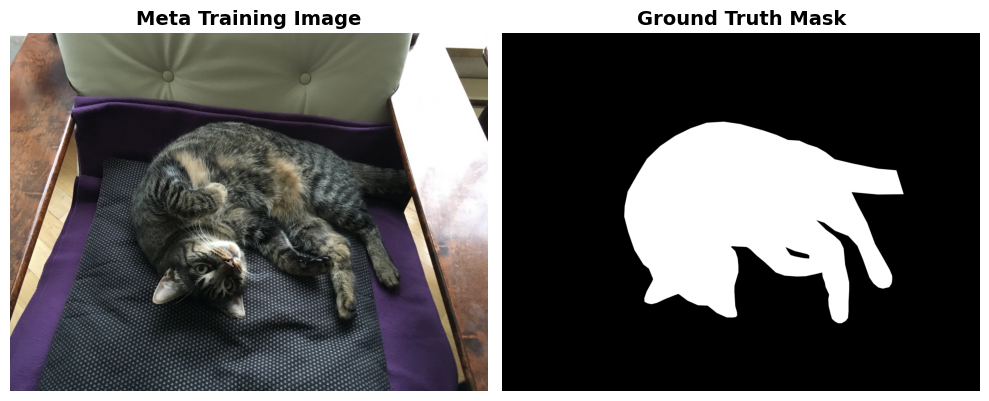

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(train_images[0])
axes[0].set_title("Meta Training Image", fontsize=14, fontweight='bold')
axes[0].axis('off')

# Plot the alpha channel mask using a gray colormap
axes[1].imshow(train_labels[0], cmap='gray')
axes[1].set_title("Ground Truth Mask", fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### **3.2 Training Loop**

In [18]:
IMAGE_SIZE = 512
PATCH_SIZE = 16

In [19]:
def resize_to_patch_multiple(img, image_size=IMAGE_SIZE, patch_size=PATCH_SIZE):
    w, h = img.size
    h_patches = int(image_size / patch_size)
    w_patches = int((w * image_size) / (h * patch_size))

    new_h = h_patches * patch_size
    new_w = w_patches * patch_size

    return img.resize((new_w, new_h), Image.Resampling.LANCZOS)

In [20]:
X_train_list = []
y_train_list = []

In [21]:
model.eval()
with torch.no_grad():
    for img, mask in zip(train_images, train_labels):

        img_resized = resize_to_patch_multiple(img)
        mask_resized = resize_to_patch_multiple(mask)

        w_new, h_new = img_resized.size
        grid_w = w_new // PATCH_SIZE
        grid_h = h_new // PATCH_SIZE

        num_spatial_patches = grid_w * grid_h

        inputs = processor(images=img_resized, return_tensors="pt", do_resize=False, do_center_crop=False).to(device)
        outputs = model(**inputs)

        patch_tokens = outputs.last_hidden_state[0, -num_spatial_patches:, :].cpu().numpy()

        mask_grid = mask_resized.resize((grid_w, grid_h), Image.Resampling.NEAREST)
        mask_array = np.array(mask_grid).flatten()

        binary_labels = (mask_array > 128).astype(int)

        X_train_list.append(patch_tokens)
        y_train_list.append(binary_labels)

In [22]:
X_train = np.vstack(X_train_list)
y_train = np.concatenate(y_train_list)
print("Training Logistic Regression model...")

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

accuracy = log_reg.score(X_train, y_train)
print(f"🎉 Model trained successfully! Training Accuracy: {accuracy * 100:.2f}%")

Training Logistic Regression model...
🎉 Model trained successfully! Training Accuracy: 99.93%


## **4. Feature Extraction**

In [23]:
import os
from tqdm import tqdm

### **4.1 Function definition**

In [ ]:
def extract_and_save_features(indices, labels, dataset, split_name):
    features_list = []
    labels_list = []

    with torch.no_grad():
        for idx, label in tqdm(zip(indices, labels), total=len(indices), desc=f"Extracting {split_name.upper()}"):

            # Grab the image and FORCE it to be RGB (prevents grayscale crashes)
            img, _ = dataset[idx]
            img = img.convert("RGB")

            # Preprocess the image and send it to the GPU
            inputs = processor(images=img, return_tensors="pt").to(device)

            # Pass through the Flagship Model
            outputs = model(**inputs)

            # Sequence = [1 CLS Token] + [N Register Tokens] + [Image Patches]
            hidden_states = outputs.last_hidden_state
            patch_features = hidden_states[0, 1 + num_registers : ]

            # Move to CPU and cast to float16
            features_list.append(patch_features.cpu().to(torch.float16))
            labels_list.append(label)

    # Save the data to your hard drive using PyTorch's native save function
    filename = f"caltech101_{split_name}_flagship_features.pt"
    save_dict = {
        "features": features_list,
        "labels": labels_list
    }

    torch.save(save_dict, filename)
    print(f"✅ Successfully saved {len(features_list)} images to {filename}\n")

### **4.2 Extracting Train and Test**

In [ ]:
extract_and_save_features(train_idx, train_labels, caltech_full, "train")

Extracting TRAIN: 100%|██████████| 6941/6941 [26:36<00:00,  4.35it/s]


✅ Successfully saved 6941 images to caltech101_train_flagship_features.pt



In [ ]:
extract_and_save_features(test_idx, test_labels, caltech_full, "test")

Extracting TEST: 100%|██████████| 1736/1736 [06:38<00:00,  4.35it/s]


✅ Successfully saved 1736 images to caltech101_test_flagship_features.pt



### **3.3 Loading the data**

In [ ]:
train_data = torch.load("caltech101_train_flagship_features.pt", weights_only=False)
test_data = torch.load("caltech101_test_flagship_features.pt", weights_only=False)

In [ ]:
caltech_train_features = [tensor.to(torch.float32).numpy() for tensor in train_data["features"]]
caltech_train_labels = train_data["labels"]

caltech_test_features = [tensor.to(torch.float32).numpy() for tensor in test_data["features"]]
caltech_test_labels = test_data["labels"]

## **5. Clustering**
We will be clustering via `FAISS` instead of standard `sklearn`

### **5.1 Imports**

In [25]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 118.7 MB/s eta 0:00:00


In [26]:
import faiss
import time
import numpy as np

### **5.2 Wrapper Class**

In [51]:
class FaissKMeansWrapper:
    def __init__(self, k, d, niter=20):
        self.k = k
        self.d = d
        self.kmeans = faiss.Kmeans(d, k, niter=niter, verbose=False, gpu=False)
        self.index = None

    def fit(self, x):
        """Trains the K-Means model to find the cluster centers."""
        self.kmeans.train(x)
        self.index = faiss.IndexFlatL2(self.d)
        self.index.add(self.kmeans.centroids)

    def predict(self, x):
        """Behaves exactly like scikit-learn"""
        if x.dtype != np.float32:
            x = x.astype(np.float32)
        distances, nearest_centroid_indices = self.index.search(x, 1)
        return nearest_centroid_indices.flatten()

### **5.3 Running the clustering**

In [ ]:
all_train_patches = np.vstack(caltech_train_features).astype(np.float32)

num_total_patches, dim = all_train_patches.shape
print(f"✅ Matrix built! Total Patches: {num_total_patches} | Dimensions: {dim}")

In [47]:
vocab_sizes = [16, 64, 256, 1024]
caltech_kmeans_models = {}

In [ ]:
for k in vocab_sizes:
    print(f"\n🧩 Training FAISS K-Means for Vocabulary Size K = {k}...")
    start_time = time.time()

    # Initialize and train our custom FAISS model
    faiss_model = FaissKMeansWrapper(k=k, d=dim)
    faiss_model.fit(all_train_patches)

    # Save it to our global dictionary so the rest of your pipeline can use it!
    caltech_kmeans_models[k] = faiss_model

    elapsed = time.time() - start_time
    print(f"   -> Completed in {elapsed:.1f} seconds!")

### **5.4 Visualisation of clusters**

In [ ]:
k_vis = 64
kmeans_model = caltech_kmeans_models[k_vis]

## **6. Data modification**

In [27]:
from sklearn.feature_extraction.text import TfidfTransformer
from collections import Counter
import matplotlib.pyplot as plt

### **6.1 Function definition**

In [ ]:
def generate_raw_counts(features_list, model, vocab_size):
    raw_counts = []
    for patches in features_list:
        labels = model.predict(patches)
        counts = np.bincount(labels, minlength=vocab_size)
        raw_counts.append(counts)
    return np.array(raw_counts)

In [ ]:
vocab_sizes = [16, 64, 256, 1024]
knn_neighbors = [1, 3, 7, 9, 11, 25]

### **6.2 Histogram Generation**

In [ ]:
caltech_raw_train_hists = {}
caltech_raw_test_hists  = {}

In [ ]:
for k in vocab_sizes:
    print(f"   -> Generating histograms for K={k}...")
    kmeans_model = caltech_kmeans_models[k]

    train_counts = generate_raw_counts(caltech_train_features, kmeans_model, k)
    test_counts = generate_raw_counts(caltech_test_features, kmeans_model, k)

    caltech_raw_train_hists[k] = train_counts
    caltech_raw_test_hists[k] = test_counts

   -> Generating histograms for K=16...
   -> Generating histograms for K=64...
   -> Generating histograms for K=256...
   -> Generating histograms for K=1024...


### **6.3 Histogram Plotting**

In [ ]:
def plot_average_class_histograms(class_names, k=64, max_cols=6):
    categories = caltech_full.categories

    # THE FIX: Create a dictionary that maps fully lowercased names to their true Caltech names and IDs
    cat_lower_to_actual = {c.lower(): (c, i) for i, c in enumerate(categories)}

    target_labels = []
    for name in class_names:
        clean_name = name.lower()

        # Check direct match
        if clean_name in cat_lower_to_actual:
            actual_name, idx = cat_lower_to_actual[clean_name]
            target_labels.append((actual_name, idx))
        # Auto-correct singular to plural (e.g., 'leopard' -> 'leopards')
        elif clean_name + "s" in cat_lower_to_actual:
            actual_name, idx = cat_lower_to_actual[clean_name + "s"]
            target_labels.append((actual_name, idx))
        else:
            print(f"⚠️ Warning: Class '{name}' not found. Try printing caltech_full.categories to see exact names!")

    num_plots = len(target_labels)
    if num_plots == 0:
        print("❌ No valid classes found to plot.")
        return

    # Calculate the dynamic grid layout
    cols = min(max_cols, num_plots)
    rows = (num_plots + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    fig.suptitle(f"Average Class Signatures (Vocab K={k})", fontsize=20, fontweight='bold', y=1.05)

    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    train_raw = caltech_raw_train_hists[k]
    caltech_train_labels_array = np.array(caltech_train_labels)

    for i, (actual_name, label_idx) in enumerate(target_labels):
        img_indices = np.where(caltech_train_labels_array == label_idx)[0]
        class_hists = train_raw[img_indices]

        # L1 Normalization
        class_hists_norm = class_hists / (np.sum(class_hists, axis=1, keepdims=True) + 1e-10)
        avg_hist = np.mean(class_hists_norm, axis=0)

        axes[i].bar(range(k), avg_hist, color='royalblue', edgecolor='black', linewidth=0.5, alpha=0.8)
        axes[i].set_title(f"{actual_name} ({len(img_indices)} imgs)", fontsize=14, fontweight='bold')
        axes[i].set_xlabel("Visual Word ID", fontsize=10)
        axes[i].set_ylabel("Average Frequency (%)", fontsize=10)
        axes[i].grid(axis='y', linestyle='--', alpha=0.5)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
classes_to_compare = [
    "leopard", "airplanes", "faces", "motorbikes",
    "flamingo", "watch", "brain", "sunflower"
]

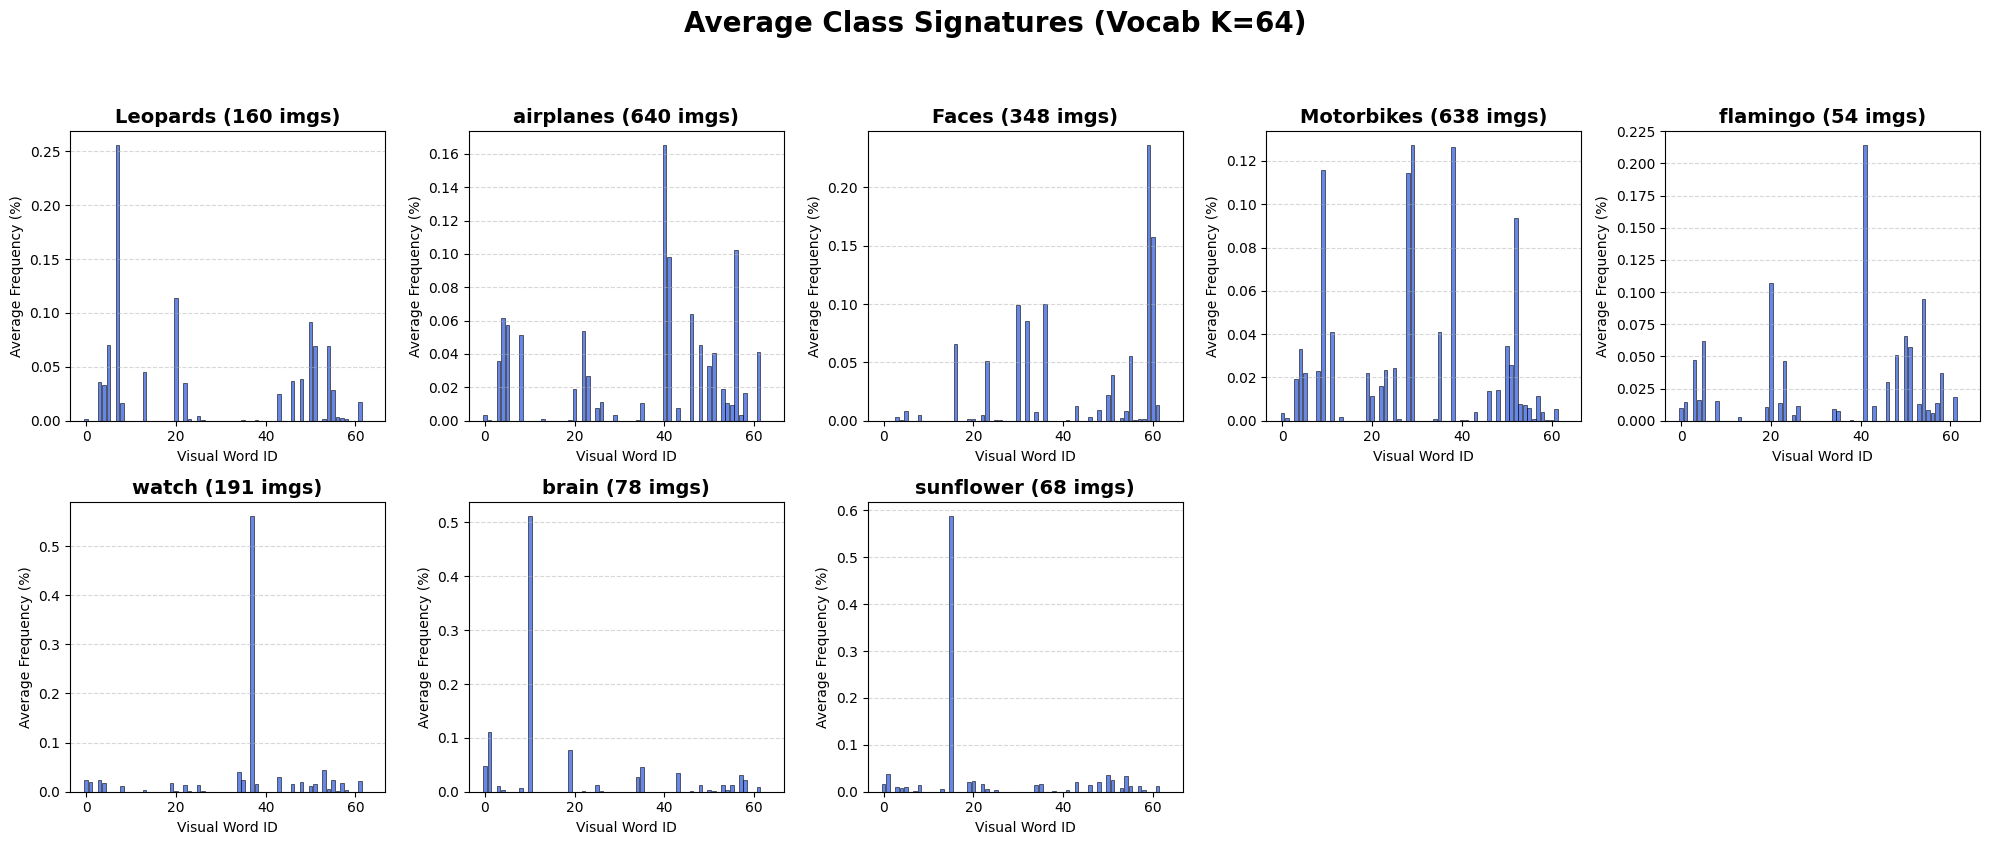

In [ ]:
plot_average_class_histograms(classes_to_compare, k=64, max_cols=5)

## **7. Chi-Square - K-NN**

### **7.1 Matrix Init**

In [ ]:
chisq_results_matrix = np.zeros((len(vocab_sizes), len(knn_neighbors)))

### **7.2 Evaluation**

In [ ]:
for i, vocab_k in enumerate(vocab_sizes):
    print(f"\n🧩 Evaluating Chi-Square for K = {vocab_k}")
    start_time = time.time()

    # LOAD FROM CACHE! No more .predict() waiting!
    train_raw = caltech_raw_train_hists[vocab_k]
    test_raw = caltech_raw_test_hists[vocab_k]

    # L1 Normalize (Convert counts to percentages) for Chi-Square
    # We add a tiny epsilon (1e-10) to prevent dividing by zero
    train_hists = train_raw / (np.sum(train_raw, axis=1, keepdims=True) + 1e-10)
    test_hists = test_raw / (np.sum(test_raw, axis=1, keepdims=True) + 1e-10)

    # Vectorized Chi-Square Distance Matrix Calculation
    num_test = len(test_hists)
    num_train = len(train_hists)
    dist_matrix = np.zeros((num_test, num_train))

    for t_idx in range(num_test):
        test_vec = test_hists[t_idx]

        # MATH MAGIC: Broadcasts the calculation across all 7,300 train images at once!
        numerator = (train_hists - test_vec) ** 2
        denominator = train_hists + test_vec + 1e-10
        dist_matrix[t_idx, :] = 0.5 * np.sum(numerator / denominator, axis=1)

    # Standard K-NN Loop
    for j, nn in enumerate(knn_neighbors):
        correct = 0
        for test_idx in range(num_test):
            distances = dist_matrix[test_idx]
            nearest_indices = np.argsort(distances)[:nn]
            nearest_labels = [caltech_train_labels[idx] for idx in nearest_indices]

            pred_label = Counter(nearest_labels).most_common(1)[0][0]
            if pred_label == caltech_test_labels[test_idx]:
                correct += 1

        accuracy = (correct / len(caltech_test_labels)) * 100
        chisq_results_matrix[i, j] = accuracy
        print(f"   -> {nn}-NN Accuracy: {accuracy:.1f}%")

    elapsed = time.time() - start_time
    print(f"   ⏱️ Completed K={vocab_k} in {elapsed:.1f} seconds")


🧩 Evaluating Chi-Square for K = 16
   -> 1-NN Accuracy: 47.6%
   -> 3-NN Accuracy: 48.4%
   -> 7-NN Accuracy: 50.1%
   -> 9-NN Accuracy: 49.9%
   -> 11-NN Accuracy: 50.1%
   -> 25-NN Accuracy: 50.1%
   ⏱️ Completed K=16 in 3.1 seconds

🧩 Evaluating Chi-Square for K = 64
   -> 1-NN Accuracy: 78.8%
   -> 3-NN Accuracy: 80.2%
   -> 7-NN Accuracy: 81.3%
   -> 9-NN Accuracy: 81.2%
   -> 11-NN Accuracy: 80.9%
   -> 25-NN Accuracy: 78.9%
   ⏱️ Completed K=64 in 5.5 seconds

🧩 Evaluating Chi-Square for K = 256
   -> 1-NN Accuracy: 91.7%
   -> 3-NN Accuracy: 93.0%
   -> 7-NN Accuracy: 93.3%
   -> 9-NN Accuracy: 92.8%
   -> 11-NN Accuracy: 92.7%
   -> 25-NN Accuracy: 92.1%
   ⏱️ Completed K=256 in 23.0 seconds

🧩 Evaluating Chi-Square for K = 1024
   -> 1-NN Accuracy: 92.3%
   -> 3-NN Accuracy: 96.2%
   -> 7-NN Accuracy: 96.8%
   -> 9-NN Accuracy: 96.9%
   -> 11-NN Accuracy: 96.9%
   -> 25-NN Accuracy: 96.9%
   ⏱️ Completed K=1024 in 124.2 seconds


### **7.3 Plotting**

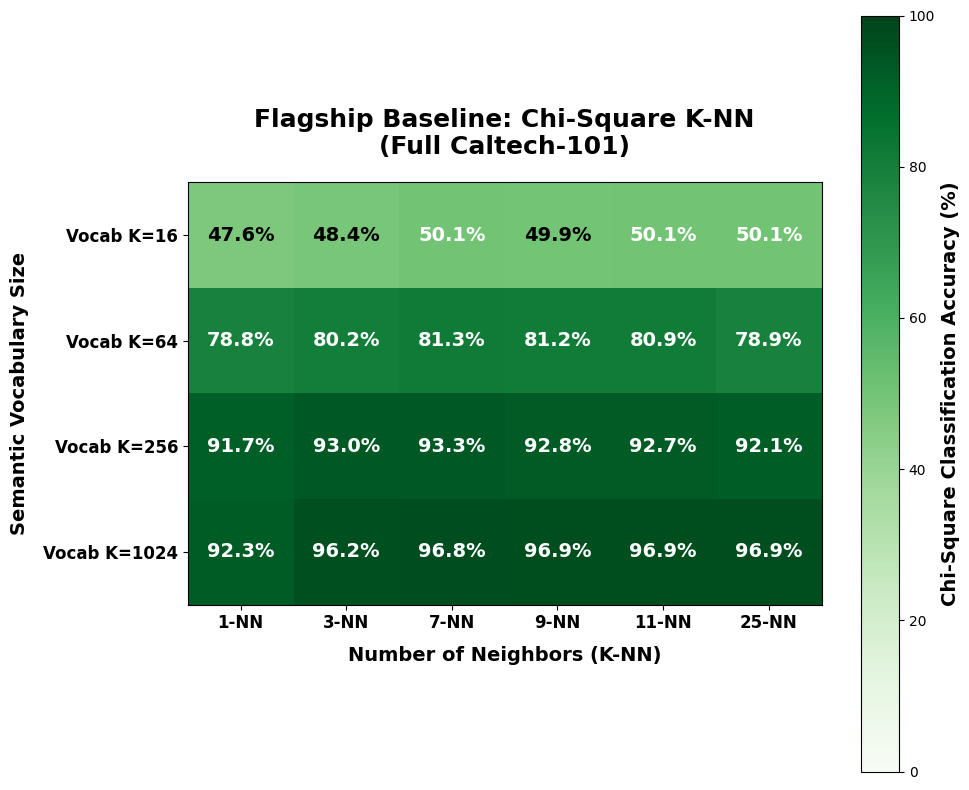

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.imshow(chisq_results_matrix, cmap='Greens', vmin=0, vmax=100)

cbar = fig.colorbar(cax)
cbar.set_label('Chi-Square Classification Accuracy (%)', fontsize=14, fontweight='bold')

ax.set_xticks(np.arange(len(knn_neighbors)))
ax.set_yticks(np.arange(len(vocab_sizes)))
ax.set_xticklabels([f"{k}-NN" for k in knn_neighbors], fontsize=12, fontweight='bold')
ax.set_yticklabels([f"Vocab K={v}" for v in vocab_sizes], fontsize=12, fontweight='bold')
ax.set_xlabel("Number of Neighbors (K-NN)", fontsize=14, fontweight='bold', labelpad=10)
ax.set_ylabel("Semantic Vocabulary Size", fontsize=14, fontweight='bold', labelpad=10)

for i in range(len(vocab_sizes)):
    for j in range(len(knn_neighbors)):
        text_color = "white" if chisq_results_matrix[i, j] > 50 else "black"
        ax.text(j, i, f"{chisq_results_matrix[i, j]:.1f}%",
                ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

ax.set_title("Flagship Baseline: Chi-Square K-NN\n(Full Caltech-101)", fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

## **8. TD-IDF**

### **8.1 Init**

In [ ]:
knn_neighbors = [1, 3, 7, 9, 11, 25]
vocab_sizes = [64, 256, 1024]
tfidf_faiss_results_matrix = np.zeros((len(vocab_sizes), len(knn_neighbors)))

### **8.2 Running the loop**

In [ ]:
for i, vocab_k in enumerate(vocab_sizes):
    print(f"\n🧩 Processing Vocabulary Size K = {vocab_k}...")
    start_time = time.time()

    # LOAD FROM CACHE! Instant access to raw histograms
    train_raw = caltech_raw_train_hists[vocab_k]
    test_raw = caltech_raw_test_hists[vocab_k]

    # Apply TF-IDF Weighting
    # This automatically penalizes the "Spam" background clusters
    tfidf_transformer = TfidfTransformer()
    train_tfidf = tfidf_transformer.fit_transform(train_raw).toarray().astype(np.float32)
    test_tfidf = tfidf_transformer.transform(test_raw).toarray().astype(np.float32)

    # The FAISS Cosine Trick (L2 Normalize + Inner Product)
    faiss.normalize_L2(train_tfidf)
    faiss.normalize_L2(test_tfidf)

    # Initialize the FAISS Inner Product Index (which now equals Cosine Similarity!)
    index = faiss.IndexFlatIP(vocab_k)
    index.add(train_tfidf)

    # Test all K-NN values instantly
    for j, nn in enumerate(knn_neighbors):
        # Search FAISS. Because it's Cosine, HIGHER scores are better!
        distances, nearest_indices = index.search(test_tfidf, nn)

        correct = 0
        for test_idx in range(len(caltech_test_labels)):
            # Filter out any weird -1 indices (just a FAISS safety net)
            valid_indices = [idx for idx in nearest_indices[test_idx] if idx != -1]
            nearest_lbls = [caltech_train_labels[idx] for idx in valid_indices]

            if nearest_lbls:
                pred_label = Counter(nearest_lbls).most_common(1)[0][0]
                if pred_label == caltech_test_labels[test_idx]:
                    correct += 1

        accuracy = (correct / len(caltech_test_labels)) * 100
        tfidf_faiss_results_matrix[i, j] = accuracy
        print(f"   -> {nn}-NN Accuracy: {accuracy:.1f}%")

    elapsed = time.time() - start_time
    print(f"   ⏱️ Completed K={vocab_k} TF-IDF Search in {elapsed:.1f} seconds")


🧩 Processing Vocabulary Size K = 64...
   -> 1-NN Accuracy: 76.9%
   -> 3-NN Accuracy: 77.9%
   -> 7-NN Accuracy: 79.0%
   -> 9-NN Accuracy: 78.3%
   -> 11-NN Accuracy: 77.9%
   -> 25-NN Accuracy: 74.7%
   ⏱️ Completed K=64 TF-IDF Search in 0.3 seconds

🧩 Processing Vocabulary Size K = 256...
   -> 1-NN Accuracy: 91.1%
   -> 3-NN Accuracy: 91.5%
   -> 7-NN Accuracy: 91.7%
   -> 9-NN Accuracy: 91.8%
   -> 11-NN Accuracy: 91.5%
   -> 25-NN Accuracy: 89.3%
   ⏱️ Completed K=256 TF-IDF Search in 0.5 seconds

🧩 Processing Vocabulary Size K = 1024...
   -> 1-NN Accuracy: 92.3%
   -> 3-NN Accuracy: 94.0%
   -> 7-NN Accuracy: 94.6%
   -> 9-NN Accuracy: 94.8%
   -> 11-NN Accuracy: 94.8%
   -> 25-NN Accuracy: 94.8%
   ⏱️ Completed K=1024 TF-IDF Search in 1.7 seconds


### **8.3 Plotting**

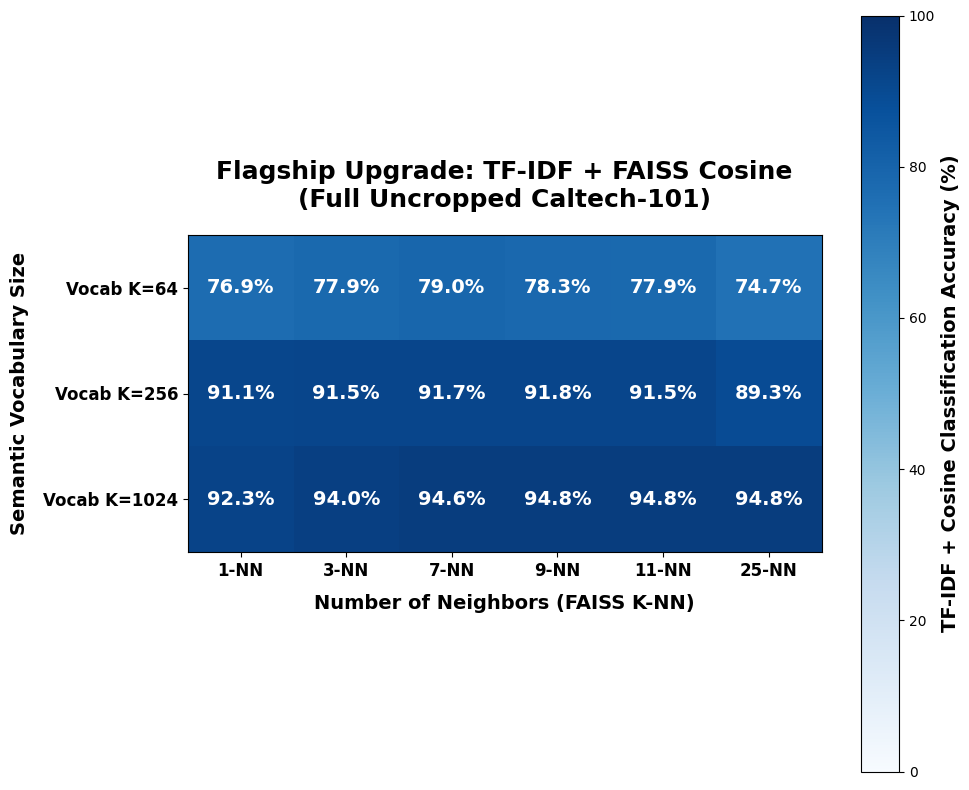

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

# Using a distinct 'Blues' colormap so you can easily compare it against the Green Chi-Square
cax = ax.imshow(tfidf_faiss_results_matrix, cmap='Blues', vmin=0, vmax=100)

cbar = fig.colorbar(cax)
cbar.set_label('TF-IDF + Cosine Classification Accuracy (%)', fontsize=14, fontweight='bold')

ax.set_xticks(np.arange(len(knn_neighbors)))
ax.set_yticks(np.arange(len(vocab_sizes)))
ax.set_xticklabels([f"{k}-NN" for k in knn_neighbors], fontsize=12, fontweight='bold')
ax.set_yticklabels([f"Vocab K={v}" for v in vocab_sizes], fontsize=12, fontweight='bold')
ax.set_xlabel("Number of Neighbors (FAISS K-NN)", fontsize=14, fontweight='bold', labelpad=10)
ax.set_ylabel("Semantic Vocabulary Size", fontsize=14, fontweight='bold', labelpad=10)

for i in range(len(vocab_sizes)):
    for j in range(len(knn_neighbors)):
        text_color = "white" if tfidf_faiss_results_matrix[i, j] > 50 else "black"
        ax.text(j, i, f"{tfidf_faiss_results_matrix[i, j]:.1f}%",
                ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

ax.set_title("Flagship Upgrade: TF-IDF + FAISS Cosine\n(Full Uncropped Caltech-101)", fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

## **9. Evaluation**

In [ ]:
import random

### **9.1 Function Definition**

In [ ]:
def plot_diagnostic_grid(error_list, method_name, num_examples=3):
    if len(error_list) < num_examples:
        num_examples = len(error_list)

    sample_errors = random.sample(error_list, num_examples)

    fig, axes = plt.subplots(num_examples, 4, figsize=(20, 4 * num_examples))
    fig.suptitle(f"Diagnostic: Why {method_name} Failed (K={k_eval})", fontsize=20, fontweight='bold', y=1.02)
    discrete_cmap = plt.get_cmap('turbo', k_eval)

    if num_examples == 1:
        axes = [axes]

    for row, (local_t_idx, local_tr_idx) in enumerate(sample_errors):
        # We safely map back to the global arrays here!
        global_test_idx = test_idx[local_t_idx]
        global_train_idx = train_idx[local_tr_idx]

        # Get Images
        test_img, _ = caltech_full[global_test_idx]
        test_img = test_img.convert("RGB").resize((224, 224))

        train_img, _ = caltech_full[global_train_idx]
        train_img = train_img.convert("RGB").resize((224, 224))

        # Get Labels
        true_label = caltech_full.categories[caltech_test_labels[local_t_idx]].title()
        wrong_label = caltech_full.categories[caltech_train_labels[local_tr_idx]].title()

        # Get Cluster Grids
        test_patches = caltech_test_features[local_t_idx]
        test_grid = kmeans_model.predict(test_patches).reshape((14, 14))

        train_patches = caltech_train_features[local_tr_idx]
        train_grid = kmeans_model.predict(train_patches).reshape((14, 14))

        # --- 1. Test Image Original ---
        axes[row][0].imshow(test_img)
        axes[row][0].set_title(f"Test Image (True: {true_label})", fontsize=14, fontweight='bold')
        axes[row][0].axis('off')

        # --- 2. Test Image Clusters ---
        axes[row][1].imshow(test_img)
        axes[row][1].imshow(test_grid, cmap=discrete_cmap, alpha=0.55, extent=[0, 224, 224, 0], vmin=-0.5, vmax=k_eval-0.5)
        axes[row][1].set_title(f"{true_label} Clusters", fontsize=14, color='darkblue')
        axes[row][1].axis('off')

        # --- 3. Wrong Match Image Original ---
        axes[row][2].imshow(train_img)
        axes[row][2].set_title(f"Closest Train (Pred: {wrong_label})", fontsize=14, color='darkred', fontweight='bold')
        axes[row][2].axis('off')

        # --- 4. Wrong Match Clusters ---
        axes[row][3].imshow(train_img)
        axes[row][3].imshow(train_grid, cmap=discrete_cmap, alpha=0.55, extent=[0, 224, 224, 0], vmin=-0.5, vmax=k_eval-0.5)
        axes[row][3].set_title(f"{wrong_label} Clusters", fontsize=14, color='darkblue')
        axes[row][3].axis('off')

    plt.tight_layout()
    plt.show()

### **9.2 Evaluation**

In [ ]:
chi_errors = []

In [30]:
total_images = len(caltech_full)
all_indices = np.arange(total_images)
all_labels = caltech_full.y

safe_train_idx, safe_test_idx, _, _ = train_test_split(
    all_indices, all_labels, test_size=0.20, random_state=42, stratify=all_labels
)

In [ ]:
k_eval = 256
kmeans_model = caltech_kmeans_models[k_eval]

In [ ]:
train_raw = caltech_raw_train_hists[k_eval]
test_raw = caltech_raw_test_hists[k_eval]

train_hists_l1 = train_raw / (np.sum(train_raw, axis=1, keepdims=True) + 1e-10)
test_hists_l1 = test_raw / (np.sum(test_raw, axis=1, keepdims=True) + 1e-10)

In [ ]:
for t_idx in range(min(500, len(test_hists_l1))):
    test_vec = test_hists_l1[t_idx]
    numerator = (train_hists_l1 - test_vec) ** 2
    denominator = train_hists_l1 + test_vec + 1e-10
    distances = 0.5 * np.sum(numerator / denominator, axis=1)

    closest_train_idx = np.argmin(distances)
    if caltech_test_labels[t_idx] != caltech_train_labels[closest_train_idx]:
        chi_errors.append((t_idx, closest_train_idx))

In [ ]:
tfidf_transformer = TfidfTransformer()
train_tfidf = tfidf_transformer.fit_transform(train_raw).toarray().astype(np.float32)
test_tfidf = tfidf_transformer.transform(test_raw).toarray().astype(np.float32)

faiss.normalize_L2(train_tfidf)
faiss.normalize_L2(test_tfidf)

index = faiss.IndexFlatIP(k_eval)
index.add(train_tfidf)
distances, nearest_indices = index.search(test_tfidf, 1)

tfidf_errors = []

In [ ]:
for t_idx in range(min(500, len(test_tfidf))):
    closest_train_idx = nearest_indices[t_idx][0]
    if caltech_test_labels[t_idx] != caltech_train_labels[closest_train_idx]:
        tfidf_errors.append((t_idx, closest_train_idx))

print(f"✅ Found {len(chi_errors)} Chi-Square errors and {len(tfidf_errors)} TF-IDF errors.")

✅ Found 235 Chi-Square errors and 50 TF-IDF errors.


### **9.3 Plotting**

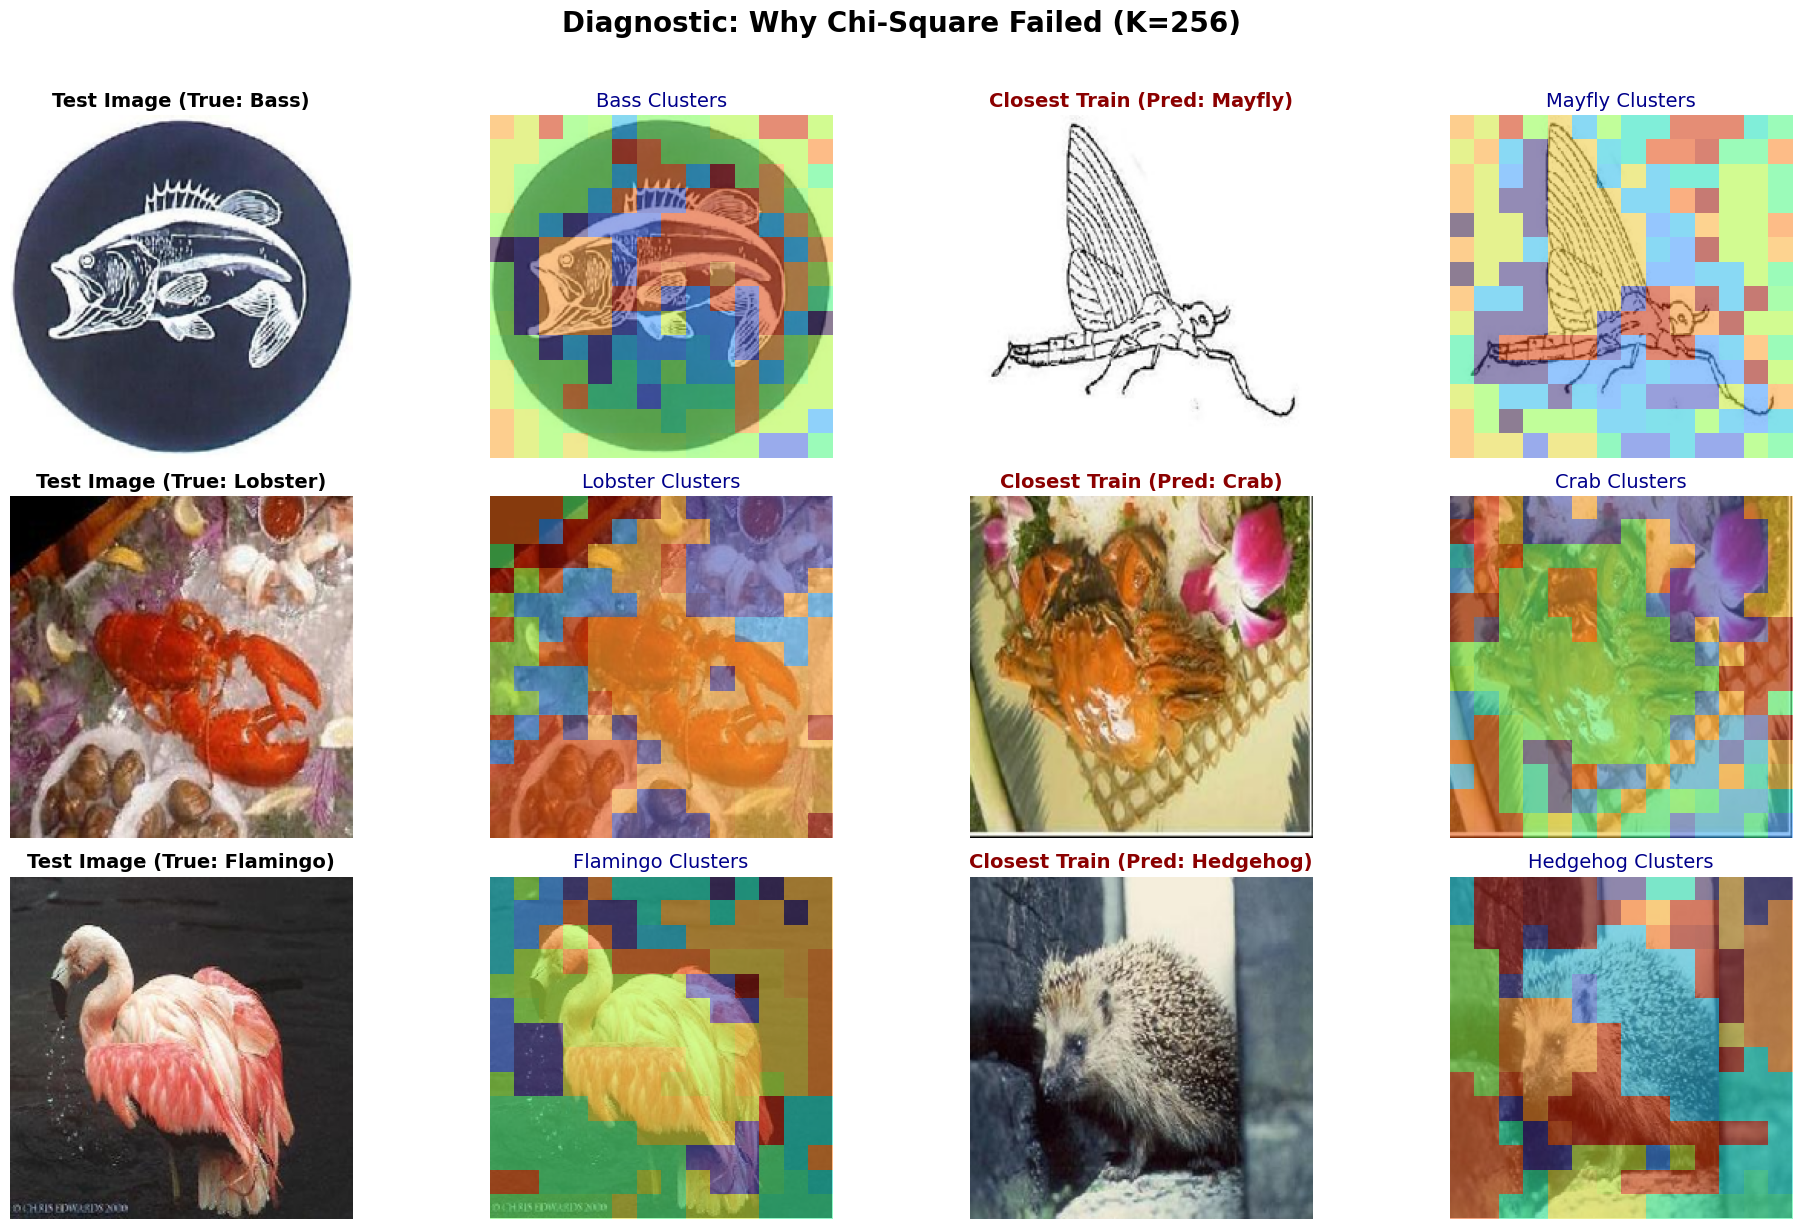

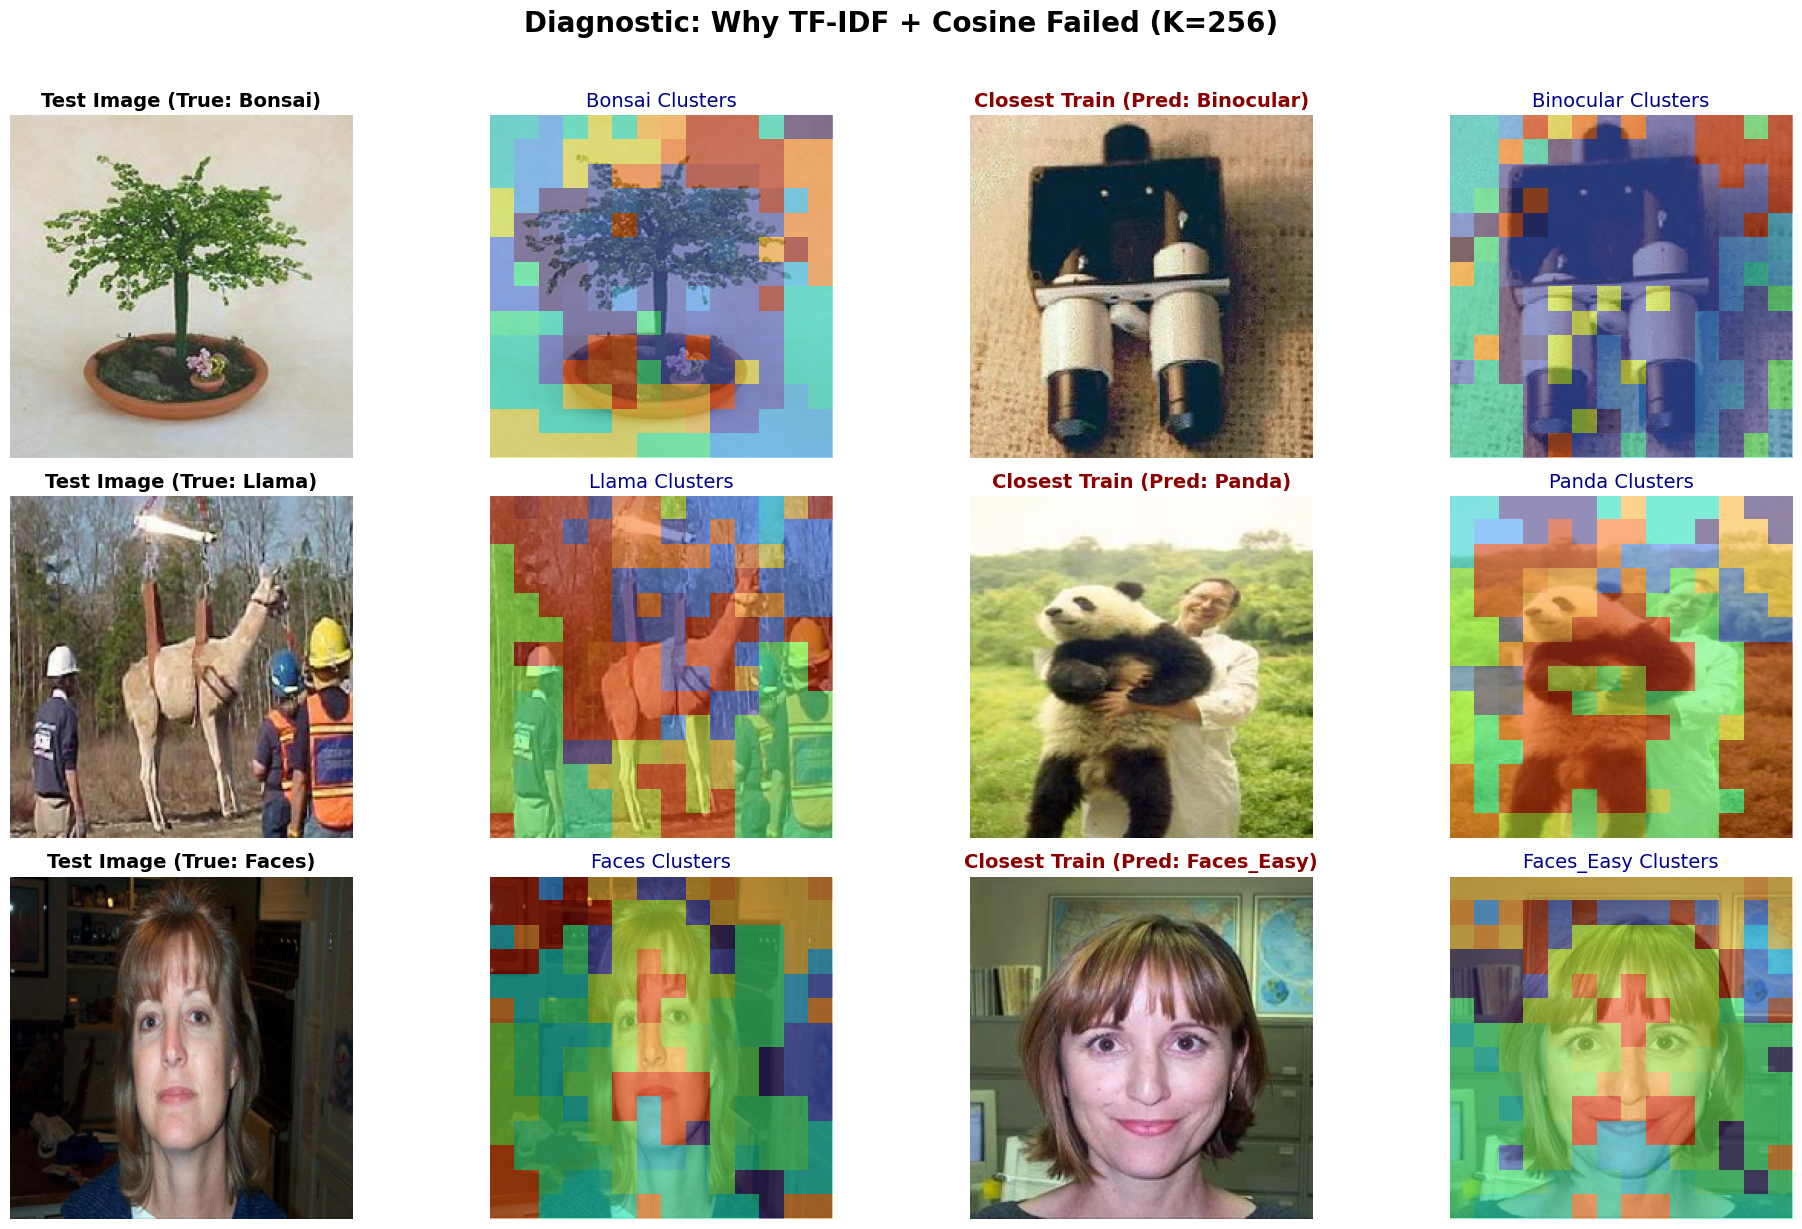

In [ ]:
plot_diagnostic_grid(chi_errors, "Chi-Square", num_examples=3)
plot_diagnostic_grid(tfidf_errors, "TF-IDF + Cosine", num_examples=3)

# **Cropping The Vectors**

## **10. Initialisation**

In [8]:
model_name = "facebook/dinov3-vitl16-pretrain-lvd1689m"

print(f"Loading flagship model: {model_name}")
print(f"Targeting Architecture: 40 Layers, 4096 Embedding Dim")

if 'dtype' not in locals():
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    #Load Model with Memory Optimization and Eager Attention
    # We strictly need eager attention to capture the attention weights
    model = AutoModel.from_pretrained(
        model_name,
        torch_dtype=torch.float32,
        low_cpu_mem_usage=True,
        attn_implementation="eager"
    ).to(device).eval()

    #Load Processor
    processor = AutoImageProcessor.from_pretrained(model_name)

    num_registers = getattr(model.config, "num_register_tokens", 4)
    print(f"Model loaded. Number of register tokens identified: {num_registers}")

    transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

    #Verify Layer Count
    if hasattr(model, "vision_model"):
        num_layers = len(model.vision_model.encoder.layers)
    else:
        #Fallback for flat architectures
        num_layers = len(model.layer)

    print(f"Success! Model loaded with {num_layers} layers.")

except Exception as e:
    print(f"Error loading model: {e}")
    print("Tip: If you run out of memory (OOM), try 'dinov3-vitl16' (Large, 24 layers) instead.")

Loading flagship model: facebook/dinov3-vitl16-pretrain-lvd1689m
Targeting Architecture: 40 Layers, 4096 Embedding Dim


config.json:   0%|          | 0.00/745 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.21G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

Model loaded. Number of register tokens identified: 4
Success! Model loaded with 24 layers.


In [ ]:
print("Training Flagship (4096d) Logistic Regression model...")

X_train_list = []
y_train_list = []

for idx, (img, mask) in enumerate(zip(train_images, train_labels)):

    patch_tokens = caltech_train_features[idx]

    img_resized = img.convert("RGB").resize((224, 224))
    mask_resized = mask.resize((224, 224))

    grid_w, grid_h = 14, 14
    mask_grid = mask_resized.resize((grid_w, grid_h), Image.Resampling.NEAREST)
    mask_array = np.array(mask_grid).flatten()

    binary_labels = (mask_array > 128).astype(int)

    X_train_list.append(patch_tokens)
    y_train_list.append(binary_labels)

X_train = np.vstack(X_train_list)
y_train = np.concatenate(y_train_list)

# Train the Flagship Cropper
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

accuracy = log_reg.score(X_train, y_train)
print(f"🎉 Flagship Cropper trained successfully! Training Accuracy: {accuracy * 100:.2f}%")

Training Flagship (4096d) Logistic Regression model...
🎉 Flagship Cropper trained successfully! Training Accuracy: 98.87%


### **10.1 Function definition**

In [ ]:
knn_neighbors = [1, 3, 7, 9, 11, 25]
vocab_sizes = [64, 256, 1024]
cropped_tfidf_results_matrix = np.zeros((len(vocab_sizes), len(knn_neighbors)))

In [ ]:
def generate_cropped_raw_counts(features_list, kmeans_model, vocab_size, log_reg_model):
    """
    Uses the trained Logistic Regression to filter out background patches
    BEFORE passing them to K-Means.
    """
    raw_counts = []

    for patches in features_list:
        # patches shape: (Num_Patches, 4096)
        binary_mask = log_reg_model.predict(patches)

        foreground_patches = patches[binary_mask == 1]

        # SAFETY NET: If the LR model hallucinates and deletes the entire image,
        # fallback to using all patches so the math doesn't crash!
        if len(foreground_patches) == 0:
            foreground_patches = patches

        # Assign the surviving foreground patches to visual words
        labels = kmeans_model.predict(foreground_patches)
        counts = np.bincount(labels, minlength=vocab_size)
        raw_counts.append(counts)

    return np.array(raw_counts)

### **10.2 Histogram Generation**

In [ ]:
caltech_cropped_train_hists = {}
caltech_cropped_test_hists = {}

for k in vocab_sizes:
    print(f"   -> Generating Cropped Histograms for K={k}...")
    kmeans_model = caltech_kmeans_models[k]

    train_counts = generate_cropped_raw_counts(caltech_train_features, kmeans_model, k, log_reg)
    test_counts = generate_cropped_raw_counts(caltech_test_features, kmeans_model, k, log_reg)

    caltech_cropped_train_hists[k] = train_counts
    caltech_cropped_test_hists[k] = test_counts

print("✅ Cropped Histograms cached!\n")

   -> Generating Cropped Histograms for K=64...
   -> Generating Cropped Histograms for K=256...
   -> Generating Cropped Histograms for K=1024...
✅ Cropped Histograms cached!



## **11. Chi-Square and FAISS L2**

### **11.1 Evaluation**

In [ ]:
cropped_chisq_results = np.zeros((len(vocab_sizes), len(knn_neighbors)))
cropped_l2_results = np.zeros((len(vocab_sizes), len(knn_neighbors)))

for i, vocab_k in enumerate(vocab_sizes):
    print(f"\n🧩 Evaluating Baselines for Cropped K = {vocab_k}")
    start_time = time.time()

    # LOAD FROM CACHE
    train_raw = caltech_cropped_train_hists[vocab_k]
    test_raw = caltech_cropped_test_hists[vocab_k]

    # L1 Normalize (Convert counts to percentages)
    train_hists_l1 = train_raw / (np.sum(train_raw, axis=1, keepdims=True) + 1e-10)
    test_hists_l1 = test_raw / (np.sum(test_raw, axis=1, keepdims=True) + 1e-10)

    num_test = len(test_hists_l1)
    num_train = len(train_hists_l1)
    dist_matrix_chisq = np.zeros((num_test, num_train))

    for t_idx in range(num_test):
        test_vec = test_hists_l1[t_idx]
        numerator = (train_hists_l1 - test_vec) ** 2
        denominator = train_hists_l1 + test_vec + 1e-10
        dist_matrix_chisq[t_idx, :] = 0.5 * np.sum(numerator / denominator, axis=1)

    # The Math Hack: Square root the normalized histograms for Hellinger Distance
    train_hellinger = np.sqrt(train_hists_l1).astype(np.float32)
    test_hellinger = np.sqrt(test_hists_l1).astype(np.float32)

    index_l2 = faiss.IndexFlatL2(vocab_k)
    index_l2.add(train_hellinger)

    # --- EVALUATE K-NN FOR BOTH ---
    for j, nn in enumerate(knn_neighbors):
        # Chi-Square Eval
        correct_chi = 0
        for test_idx in range(num_test):
            nearest_indices_chi = np.argsort(dist_matrix_chisq[test_idx])[:nn]
            nearest_labels_chi = [caltech_train_labels[idx] for idx in nearest_indices_chi]
            pred_chi = Counter(nearest_labels_chi).most_common(1)[0][0]
            if pred_chi == caltech_test_labels[test_idx]:
                correct_chi += 1
        cropped_chisq_results[i, j] = (correct_chi / num_test) * 100

        # FAISS L2 Eval (LOWER distance is better in L2)
        distances_l2, nearest_indices_l2 = index_l2.search(test_hellinger, nn)
        correct_l2 = 0
        for test_idx in range(num_test):
            valid_indices_l2 = [idx for idx in nearest_indices_l2[test_idx] if idx != -1]
            nearest_labels_l2 = [caltech_train_labels[idx] for idx in valid_indices_l2]
            if nearest_labels_l2:
                pred_l2 = Counter(nearest_labels_l2).most_common(1)[0][0]
                if pred_l2 == caltech_test_labels[test_idx]:
                    correct_l2 += 1
        cropped_l2_results[i, j] = (correct_l2 / num_test) * 100

    elapsed = time.time() - start_time
    print(f"   ⏱️ Completed K={vocab_k} in {elapsed:.1f} seconds")


🧩 Evaluating Baselines for Cropped K = 64
   ⏱️ Completed K=64 in 5.7 seconds

🧩 Evaluating Baselines for Cropped K = 256
   ⏱️ Completed K=256 in 23.0 seconds

🧩 Evaluating Baselines for Cropped K = 1024
   ⏱️ Completed K=1024 in 127.5 seconds


### **11.2 Plotting**

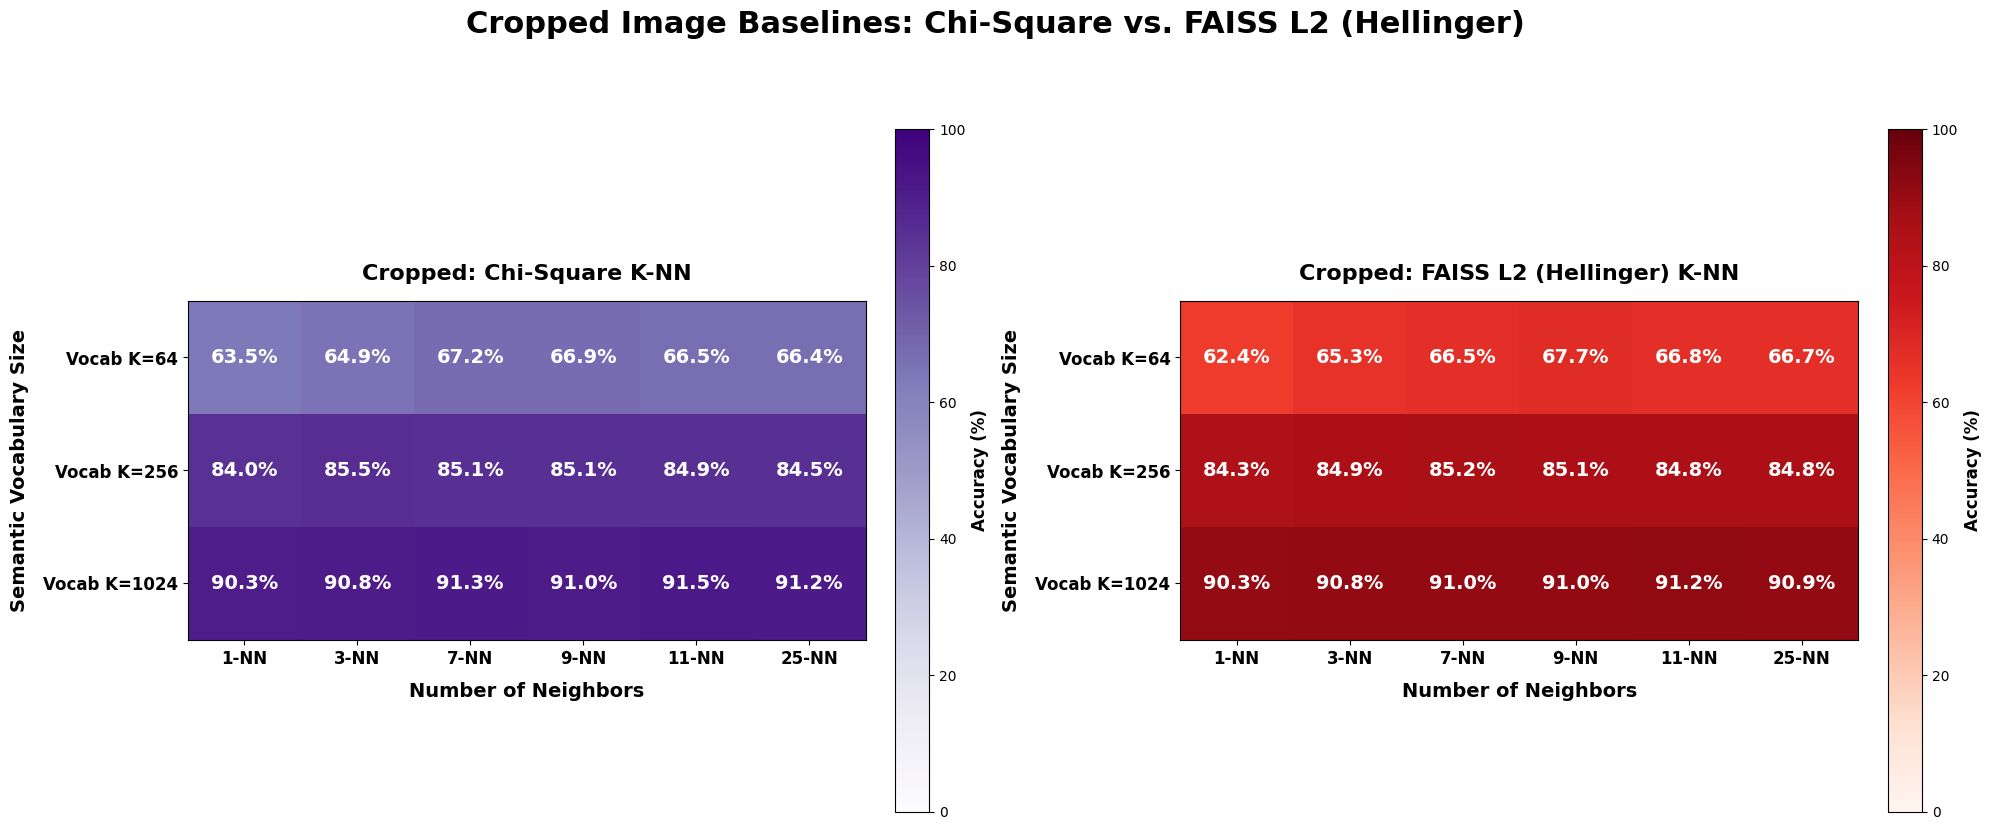

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle("Cropped Image Baselines: Chi-Square vs. FAISS L2 (Hellinger)", fontsize=22, fontweight='bold', y=1.05)

# Plot Cropped Chi-Square
cax1 = axes[0].imshow(cropped_chisq_results, cmap='Purples', vmin=0, vmax=100)
cbar1 = fig.colorbar(cax1, ax=axes[0], fraction=0.046, pad=0.04)
cbar1.set_label('Accuracy (%)', fontsize=12, fontweight='bold')
axes[0].set_title("Cropped: Chi-Square K-NN", fontsize=16, fontweight='bold', pad=15)

# Plot Cropped FAISS L2
cax2 = axes[1].imshow(cropped_l2_results, cmap='Reds', vmin=0, vmax=100)
cbar2 = fig.colorbar(cax2, ax=axes[1], fraction=0.046, pad=0.04)
cbar2.set_label('Accuracy (%)', fontsize=12, fontweight='bold')
axes[1].set_title("Cropped: FAISS L2 (Hellinger) K-NN", fontsize=16, fontweight='bold', pad=15)

for ax, matrix in zip(axes, [cropped_chisq_results, cropped_l2_results]):
    ax.set_xticks(np.arange(len(knn_neighbors)))
    ax.set_yticks(np.arange(len(vocab_sizes)))
    ax.set_xticklabels([f"{k}-NN" for k in knn_neighbors], fontsize=12, fontweight='bold')
    ax.set_yticklabels([f"Vocab K={v}" for v in vocab_sizes], fontsize=12, fontweight='bold')
    ax.set_xlabel("Number of Neighbors", fontsize=14, fontweight='bold', labelpad=10)
    ax.set_ylabel("Semantic Vocabulary Size", fontsize=14, fontweight='bold', labelpad=10)

    for i in range(len(vocab_sizes)):
        for j in range(len(knn_neighbors)):
            text_color = "white" if matrix[i, j] > 50 else "black"
            ax.text(j, i, f"{matrix[i, j]:.1f}%",
                    ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## **12. TD-IDF**

In [ ]:
cropped_tfidf_results = np.zeros((len(vocab_sizes), len(knn_neighbors)))

### **12.1 Running the thing**

In [ ]:
for i, vocab_k in enumerate(vocab_sizes):
    print(f"\n🧩 Weighting and Searching Cropped K = {vocab_k}...")
    start_time = time.time()

    train_raw = caltech_cropped_train_hists[vocab_k]
    test_raw = caltech_cropped_test_hists[vocab_k]

    # This automatically finds the "Spam" words in the cropped animals and penalizes them
    tfidf_transformer = TfidfTransformer()
    train_tfidf = tfidf_transformer.fit_transform(train_raw).toarray().astype(np.float32)
    test_tfidf = tfidf_transformer.transform(test_raw).toarray().astype(np.float32)

    # FAISS COSINE TRICK
    # L2 Normalize the vectors so Inner Product becomes Cosine Similarity
    faiss.normalize_L2(train_tfidf)
    faiss.normalize_L2(test_tfidf)

    index_cosine = faiss.IndexFlatIP(vocab_k)
    index_cosine.add(train_tfidf)

    # EVALUATE K-NN
    for j, nn in enumerate(knn_neighbors):
        # Higher score is better for Cosine (Inner Product)
        distances, nearest_indices = index_cosine.search(test_tfidf, nn)

        correct = 0
        for test_idx in range(len(caltech_test_labels)):
            valid_indices = [idx for idx in nearest_indices[test_idx] if idx != -1]
            nearest_labels = [caltech_train_labels[idx] for idx in valid_indices]

            if nearest_labels:
                pred = Counter(nearest_labels).most_common(1)[0][0]
                if pred == caltech_test_labels[test_idx]:
                    correct += 1

        accuracy = (correct / len(caltech_test_labels)) * 100
        cropped_tfidf_results[i, j] = accuracy
        print(f"   -> {nn}-NN Accuracy: {accuracy:.1f}%")

    elapsed = time.time() - start_time
    print(f"   ⏱️ Completed K={vocab_k} TF-IDF in {elapsed:.1f} seconds")


🧩 Weighting and Searching Cropped K = 64...
   -> 1-NN Accuracy: 61.8%
   -> 3-NN Accuracy: 63.9%
   -> 7-NN Accuracy: 64.6%
   -> 9-NN Accuracy: 64.7%
   -> 11-NN Accuracy: 64.7%
   -> 25-NN Accuracy: 63.8%
   ⏱️ Completed K=64 TF-IDF in 0.3 seconds

🧩 Weighting and Searching Cropped K = 256...
   -> 1-NN Accuracy: 83.6%
   -> 3-NN Accuracy: 84.6%
   -> 7-NN Accuracy: 83.9%
   -> 9-NN Accuracy: 83.9%
   -> 11-NN Accuracy: 84.3%
   -> 25-NN Accuracy: 83.5%
   ⏱️ Completed K=256 TF-IDF in 0.5 seconds

🧩 Weighting and Searching Cropped K = 1024...
   -> 1-NN Accuracy: 89.4%
   -> 3-NN Accuracy: 90.6%
   -> 7-NN Accuracy: 91.1%
   -> 9-NN Accuracy: 90.8%
   -> 11-NN Accuracy: 91.0%
   -> 25-NN Accuracy: 91.2%
   ⏱️ Completed K=1024 TF-IDF in 1.7 seconds


### **12.2 Plotting**

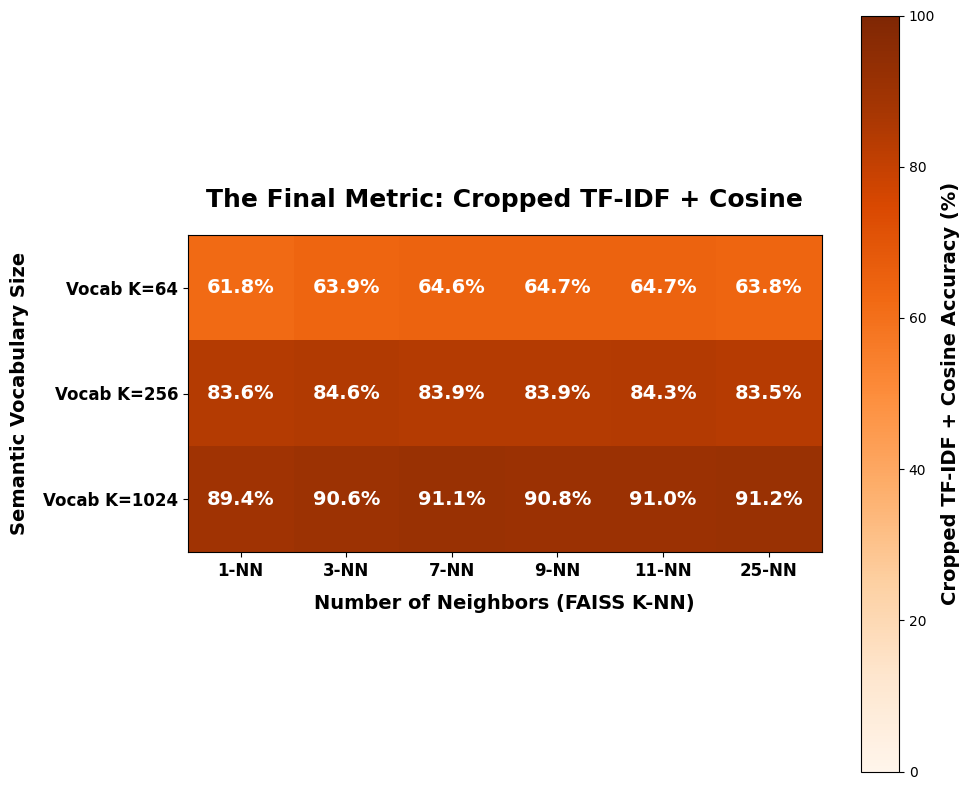

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

cax = ax.imshow(cropped_tfidf_results, cmap='Oranges', vmin=0, vmax=100)

cbar = fig.colorbar(cax)
cbar.set_label('Cropped TF-IDF + Cosine Accuracy (%)', fontsize=14, fontweight='bold')

ax.set_xticks(np.arange(len(knn_neighbors)))
ax.set_yticks(np.arange(len(vocab_sizes)))
ax.set_xticklabels([f"{k}-NN" for k in knn_neighbors], fontsize=12, fontweight='bold')
ax.set_yticklabels([f"Vocab K={v}" for v in vocab_sizes], fontsize=12, fontweight='bold')
ax.set_xlabel("Number of Neighbors (FAISS K-NN)", fontsize=14, fontweight='bold', labelpad=10)
ax.set_ylabel("Semantic Vocabulary Size", fontsize=14, fontweight='bold', labelpad=10)

for i in range(len(vocab_sizes)):
    for j in range(len(knn_neighbors)):
        text_color = "white" if cropped_tfidf_results[i, j] > 50 else "black"
        ax.text(j, i, f"{cropped_tfidf_results[i, j]:.1f}%",
                ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

ax.set_title("The Final Metric: Cropped TF-IDF + Cosine", fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# **Cropping the images**

In [38]:
import random

In [ ]:
total_images = len(caltech_full)
all_indices = np.arange(total_images)
all_labels = caltech_full.y

safe_train_idx, safe_test_idx, _, _ = train_test_split(
    all_indices, all_labels, test_size=0.20, random_state=42, stratify=all_labels
)
print(f"✅ Split successful: {len(safe_train_idx)} Train images, {len(safe_test_idx)} Test images.")

✅ Split successful: 6941 Train images, 1736 Test images.


## **13. Imports and preperation**

In [32]:
def true_end_to_end_crop(img, model, processor, log_reg_model, device, num_registers):
    # TRANSLATE IMAGE FOR THE LOGISTIC REGRESSION
    inputs_raw = processor(images=img, return_tensors="pt").to(device)
    outputs_raw = model(**inputs_raw)
    raw_patches = outputs_raw.last_hidden_state[0, 1 + num_registers : ].cpu().numpy().astype(np.float32)

    # THE LOGISTIC REGRESSION CROPS IT
    mask_1d = log_reg_model.predict(raw_patches)
    mask_2d = mask_1d.reshape(14, 14).astype(np.uint8) * 255

    # Resize to fit the original image
    mask_pil = Image.fromarray(mask_2d).resize(img.size, Image.Resampling.NEAREST)
    mask_array = (np.array(mask_pil) > 128).astype(np.uint8)

    # Black out and crop
    img_array = np.array(img.convert("RGB"))
    mask_3d = np.expand_dims(mask_array, axis=-1)
    blacked_out_img = (img_array * mask_3d).astype(np.uint8)

    coords = np.argwhere(mask_array > 0)

    if coords.size == 0:
        cropped_img = img.convert("RGB")
    else:
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        cropped_array = blacked_out_img[y_min:y_max+1, x_min:x_max+1]
        cropped_img = Image.fromarray(cropped_array)

    inputs_cropped = processor(images=cropped_img, return_tensors="pt").to(device)
    outputs_cropped = model(**inputs_cropped)

    final_patches = outputs_cropped.last_hidden_state[0, 1 + num_registers : ].cpu().numpy().astype(np.float32)

    return final_patches

## **14. Segmentation**

### **14.1 Init**

In [28]:
zoomed_train_features = []
zoomed_test_features = []

In [ ]:
with torch.no_grad():
    print("🚀 Extracting NEW Zoomed Train Features...")

    # Loop over every single index in your Training split
    for idx in tqdm(safe_train_idx, desc="Zoomed Train Extraction"):
        img, _ = caltech_full[idx]
        img_rgb = img.convert("RGB") # Safety first!

        final_patches = true_end_to_end_crop(img_rgb, model, processor, log_reg, device, num_registers)
        zoomed_train_features.append(final_patches)

    print("\n🚀 Extracting NEW Zoomed Test Features...")

    # Loop over every single index in your Testing split
    for idx in tqdm(safe_test_idx, desc="Zoomed Test Extraction"):
        img, _ = caltech_full[idx]
        img_rgb = img.convert("RGB")

        final_patches = true_end_to_end_crop(img_rgb, model, processor, log_reg, device, num_registers)
        zoomed_test_features.append(final_patches)

### **14.2 Saving the features**

In [34]:
print("\n✅ Success! The End-to-End Cropper finished the entire dataset.")
caltech_zoomed_train_features = np.array(zoomed_train_features)
caltech_zoomed_test_features = np.array(zoomed_test_features)


✅ Success! The End-to-End Cropper finished the entire dataset.


In [35]:
# Highly recommended: Save these to disk so you don't lose them if Colab disconnects!
np.save("caltech_zoomed_train_features.npy", caltech_zoomed_train_features)
np.save("caltech_zoomed_test_features.npy", caltech_zoomed_test_features)
print("💾 Features safely backed up to disk as .npy files!")

💾 Features safely backed up to disk as .npy files!


### **14.3 Visualisation**

In [39]:
def peek_at_zoomed_crops(images_to_test, model, processor, log_reg_model, device, num_registers):
    fig, axes = plt.subplots(1, len(images_to_test), figsize=(16, 4))
    fig.suptitle("What the Model Actually Saw (Zoomed & Blacked Out)", fontsize=18, fontweight='bold', y=1.05)

    if len(images_to_test) == 1:
        axes = [axes]

    for col, img in enumerate(images_to_test):
        inputs_raw = processor(images=img, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs_raw = model(**inputs_raw)
        raw_patches = outputs_raw.last_hidden_state[0, 1 + num_registers : ].cpu().numpy().astype(np.float32)

        mask_1d = log_reg_model.predict(raw_patches)
        mask_2d = mask_1d.reshape(14, 14).astype(np.uint8) * 255
        mask_pil = Image.fromarray(mask_2d).resize(img.size, Image.Resampling.NEAREST)
        mask_array = (np.array(mask_pil) > 128).astype(np.uint8)

        img_array = np.array(img.convert("RGB"))
        mask_3d = np.expand_dims(mask_array, axis=-1)
        blacked_out_img = (img_array * mask_3d).astype(np.uint8)

        coords = np.argwhere(mask_array > 0)
        if coords.size == 0:
            cropped_img = img_array
        else:
            y_min, x_min = coords.min(axis=0)
            y_max, x_max = coords.max(axis=0)
            cropped_img = blacked_out_img[y_min:y_max+1, x_min:x_max+1]

        axes[col].imshow(cropped_img)
        axes[col].axis('off')

    plt.tight_layout()
    plt.show()

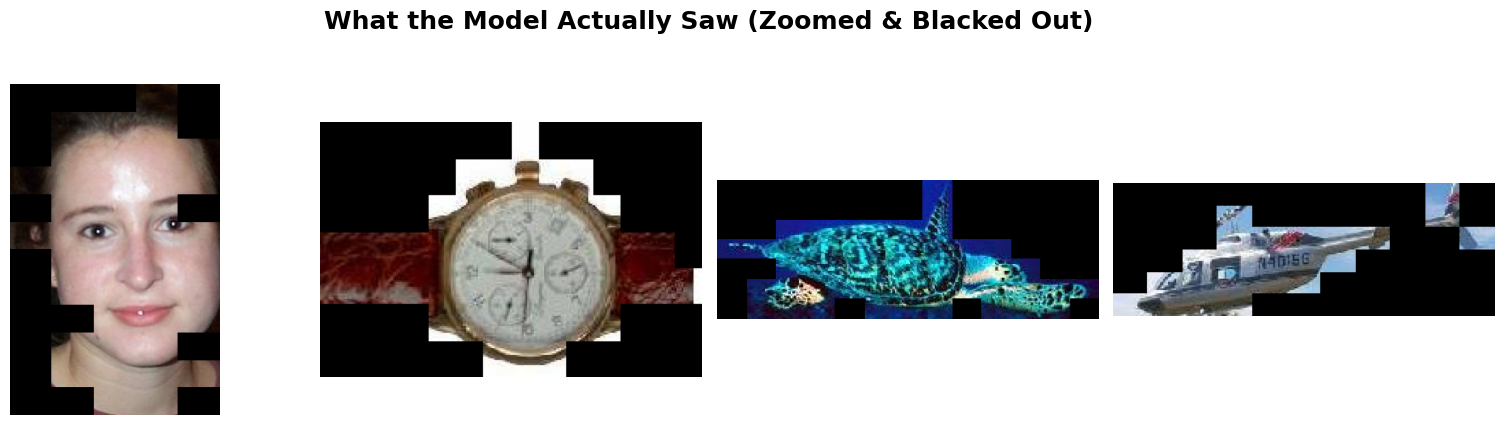

In [41]:
model.eval()
sample_indices = random.sample(list(safe_train_idx), 4)
sample_imgs = [caltech_full[idx][0].convert("RGB") for idx in sample_indices]

peek_at_zoomed_crops(sample_imgs, model, processor, log_reg, device, num_registers)

## **15. Chi-Square**

### **15.1 Init**

In [58]:
zoomed_chisq_results = np.zeros((len(vocab_sizes), len(knn_neighbors)))

caltech_zoomed_train_hists = {}
caltech_zoomed_test_hists = {}

### **15.2 Clustering**

In [59]:
flat_zoomed_train = caltech_zoomed_train_features.reshape(-1, caltech_zoomed_train_features.shape[-1]).astype(np.float32)
d = flat_zoomed_train.shape[1] # Should be 4096

In [54]:
vocab_sizes = [16, 64, 256, 1024]
caltech_kmeans_models = {}

for k in vocab_sizes:
    start_time = time.time()

    # Initialize and train our custom FAISS K-Means
    faiss_kmeans = FaissKMeansWrapper(k, d)
    faiss_kmeans.fit(flat_zoomed_train)

    caltech_kmeans_models[k] = faiss_kmeans
    print(f"      ✅ K={k} FAISS Dictionary built in {time.time() - start_time:.1f} seconds.")

print("🚀 All FAISS K-Means dictionaries ready for action!")

      ✅ K=16 FAISS Dictionary built in 1.1 seconds.
      ✅ K=64 FAISS Dictionary built in 1.7 seconds.
      ✅ K=256 FAISS Dictionary built in 8.7 seconds.
      ✅ K=1024 FAISS Dictionary built in 104.2 seconds.
🚀 All FAISS K-Means dictionaries ready for action!


In [60]:
vocab_sizes = sorted(list(caltech_kmeans_models.keys()))
knn_neighbors = [1, 3, 7, 9, 11, 25]

zoomed_chisq_results = np.zeros((len(vocab_sizes), len(knn_neighbors)))

### **15.3 Evaluation**

In [61]:
for i, vocab_k in enumerate(vocab_sizes):
    print(f"\n🧩 Processing Zoomed Vocabulary Size K = {vocab_k}...")
    start_time = time.time()

    kmeans_model = caltech_kmeans_models[vocab_k]

    train_hists = []
    for feats in caltech_zoomed_train_features:
        labels = kmeans_model.predict(feats)
        train_hists.append(np.bincount(labels, minlength=vocab_k))
    train_hists = np.array(train_hists)

    test_hists = []
    for feats in caltech_zoomed_test_features:
        labels = kmeans_model.predict(feats)
        test_hists.append(np.bincount(labels, minlength=vocab_k))
    test_hists = np.array(test_hists)

    caltech_zoomed_train_hists[vocab_k] = train_hists
    caltech_zoomed_test_hists[vocab_k] = test_hists

    train_hists_l1 = train_hists / (np.sum(train_hists, axis=1, keepdims=True) + 1e-10)
    test_hists_l1 = test_hists / (np.sum(test_hists, axis=1, keepdims=True) + 1e-10)

    num_test = len(test_hists_l1)
    num_train = len(train_hists_l1)
    dist_matrix = np.zeros((num_test, num_train))

    for t_idx in range(num_test):
        test_vec = test_hists_l1[t_idx]
        numerator = (train_hists_l1 - test_vec) ** 2
        denominator = train_hists_l1 + test_vec + 1e-10
        dist_matrix[t_idx, :] = 0.5 * np.sum(numerator / denominator, axis=1)

    for j, nn in enumerate(knn_neighbors):
        correct = 0
        for test_idx in range(num_test):
            nearest_indices = np.argsort(dist_matrix[test_idx])[:nn]

            nearest_labels = [caltech_full.y[safe_train_idx[idx]] for idx in nearest_indices]
            true_label = caltech_full.y[safe_test_idx[test_idx]]

            pred_label = Counter(nearest_labels).most_common(1)[0][0]
            if pred_label == true_label:
                correct += 1

        accuracy = (correct / num_test) * 100
        zoomed_chisq_results[i, j] = accuracy
        print(f"   -> {nn}-NN Accuracy: {accuracy:.1f}%")

    elapsed = time.time() - start_time
    print(f"   ⏱️ Completed K={vocab_k} in {elapsed:.1f} seconds")


🧩 Processing Zoomed Vocabulary Size K = 16...
   -> 1-NN Accuracy: 42.5%
   -> 3-NN Accuracy: 43.3%
   -> 7-NN Accuracy: 45.5%
   -> 9-NN Accuracy: 46.0%
   -> 11-NN Accuracy: 46.0%
   -> 25-NN Accuracy: 46.1%
   ⏱️ Completed K=16 in 4.9 seconds

🧩 Processing Zoomed Vocabulary Size K = 64...
   -> 1-NN Accuracy: 68.7%
   -> 3-NN Accuracy: 69.9%
   -> 7-NN Accuracy: 71.8%
   -> 9-NN Accuracy: 71.9%
   -> 11-NN Accuracy: 72.1%
   -> 25-NN Accuracy: 71.6%
   ⏱️ Completed K=64 in 9.2 seconds

🧩 Processing Zoomed Vocabulary Size K = 256...
   -> 1-NN Accuracy: 87.0%
   -> 3-NN Accuracy: 88.2%
   -> 7-NN Accuracy: 88.5%
   -> 9-NN Accuracy: 88.3%
   -> 11-NN Accuracy: 88.2%
   -> 25-NN Accuracy: 87.5%
   ⏱️ Completed K=256 in 33.9 seconds

🧩 Processing Zoomed Vocabulary Size K = 1024...
   -> 1-NN Accuracy: 89.9%
   -> 3-NN Accuracy: 90.8%
   -> 7-NN Accuracy: 91.2%
   -> 9-NN Accuracy: 91.5%
   -> 11-NN Accuracy: 91.2%
   -> 25-NN Accuracy: 90.1%
   ⏱️ Completed K=1024 in 168.2 seconds


### **15.4 Plotting**

In [62]:
# Plotting Function
def plot_zoomed_diagnostic_grid(error_list, num_examples=3):
    if len(error_list) < num_examples:
        num_examples = len(error_list)

    sample_errors = random.sample(error_list, num_examples)
    fig, axes = plt.subplots(num_examples, 4, figsize=(20, 4 * num_examples))
    fig.suptitle(f"Diagnostic: Zoomed Chi-Square Failures (K={k_eval})", fontsize=20, fontweight='bold', y=1.02)
    discrete_cmap = plt.get_cmap('turbo', k_eval)

    if num_examples == 1: axes = [axes]

    for row, (local_t_idx, local_tr_idx) in enumerate(sample_errors):
        global_test_idx = safe_test_idx[local_t_idx]
        global_train_idx = safe_train_idx[local_tr_idx]

        # We plot the ORIGINAL images here just so you can see what the subjects were
        test_img, test_lbl_idx = caltech_full[global_test_idx]
        test_img = test_img.convert("RGB").resize((224, 224))

        train_img, train_lbl_idx = caltech_full[global_train_idx]
        train_img = train_img.convert("RGB").resize((224, 224))

        true_label = caltech_full.categories[test_lbl_idx].title()
        wrong_label = caltech_full.categories[train_lbl_idx].title()

        # Grab the Zoomed Patches
        test_patches = caltech_zoomed_test_features[local_t_idx]
        test_grid = kmeans_model.predict(test_patches).reshape((14, 14))

        train_patches = caltech_zoomed_train_features[local_tr_idx]
        train_grid = kmeans_model.predict(train_patches).reshape((14, 14))

        axes[row][0].imshow(test_img)
        axes[row][0].set_title(f"Test Image (True: {true_label})", fontsize=14, fontweight='bold')
        axes[row][0].axis('off')

        axes[row][1].imshow(test_img)
        axes[row][1].imshow(test_grid, cmap=discrete_cmap, alpha=0.55, extent=[0, 224, 224, 0], vmin=-0.5, vmax=k_eval-0.5)
        axes[row][1].set_title(f"Zoomed Clusters", fontsize=14, color='darkblue')
        axes[row][1].axis('off')

        axes[row][2].imshow(train_img)
        axes[row][2].set_title(f"Closest Train (Pred: {wrong_label})", fontsize=14, color='darkred', fontweight='bold')
        axes[row][2].axis('off')

        axes[row][3].imshow(train_img)
        axes[row][3].imshow(train_grid, cmap=discrete_cmap, alpha=0.55, extent=[0, 224, 224, 0], vmin=-0.5, vmax=k_eval-0.5)
        axes[row][3].set_title(f"Zoomed Clusters", fontsize=14, color='darkblue')
        axes[row][3].axis('off')

    plt.tight_layout()
    plt.show()

In [63]:
k_eval = 64
kmeans_model = caltech_kmeans_models[k_eval]

# Grab the cached zoomed histograms
train_raw = caltech_zoomed_train_hists[k_eval]
test_raw = caltech_zoomed_test_hists[k_eval]

# L1 Normalize for Chi-Square
train_hists_l1 = train_raw / (np.sum(train_raw, axis=1, keepdims=True) + 1e-10)
test_hists_l1 = test_raw / (np.sum(test_raw, axis=1, keepdims=True) + 1e-10)

zoomed_chi_errors = []

In [64]:
for t_idx in range(min(500, len(test_hists_l1))):
    test_vec = test_hists_l1[t_idx]
    numerator = (train_hists_l1 - test_vec) ** 2
    denominator = train_hists_l1 + test_vec + 1e-10
    distances = 0.5 * np.sum(numerator / denominator, axis=1)

    closest_train_idx = np.argmin(distances)

    true_label = caltech_full.y[safe_test_idx[t_idx]]
    pred_label = caltech_full.y[safe_train_idx[closest_train_idx]]

    if true_label != pred_label:
        zoomed_chi_errors.append((t_idx, closest_train_idx))

print(f"✅ Found {len(zoomed_chi_errors)} mistakes in the sample. Plotting...")

✅ Found 172 mistakes in the sample. Plotting...


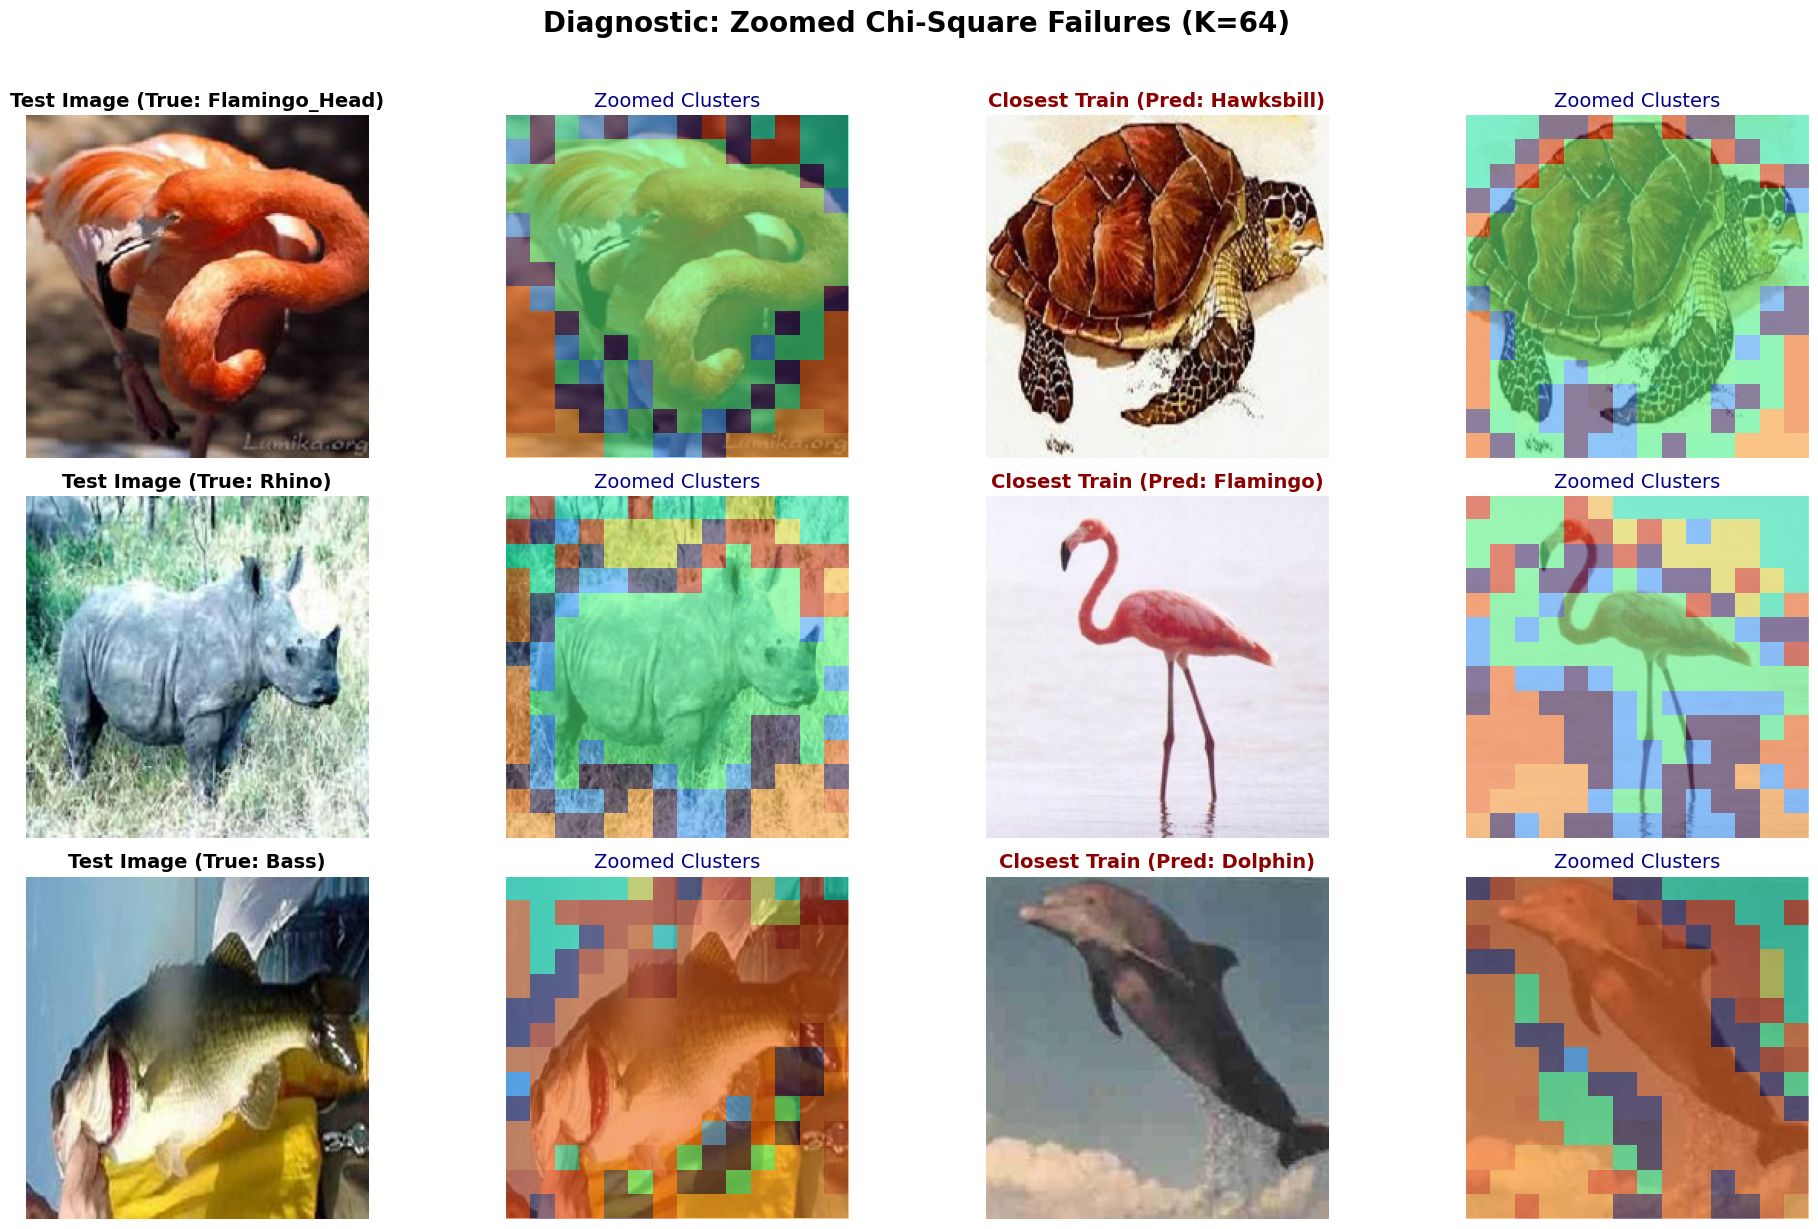

In [65]:
plot_zoomed_diagnostic_grid(zoomed_chi_errors, num_examples=3)

### **15.5 Results**

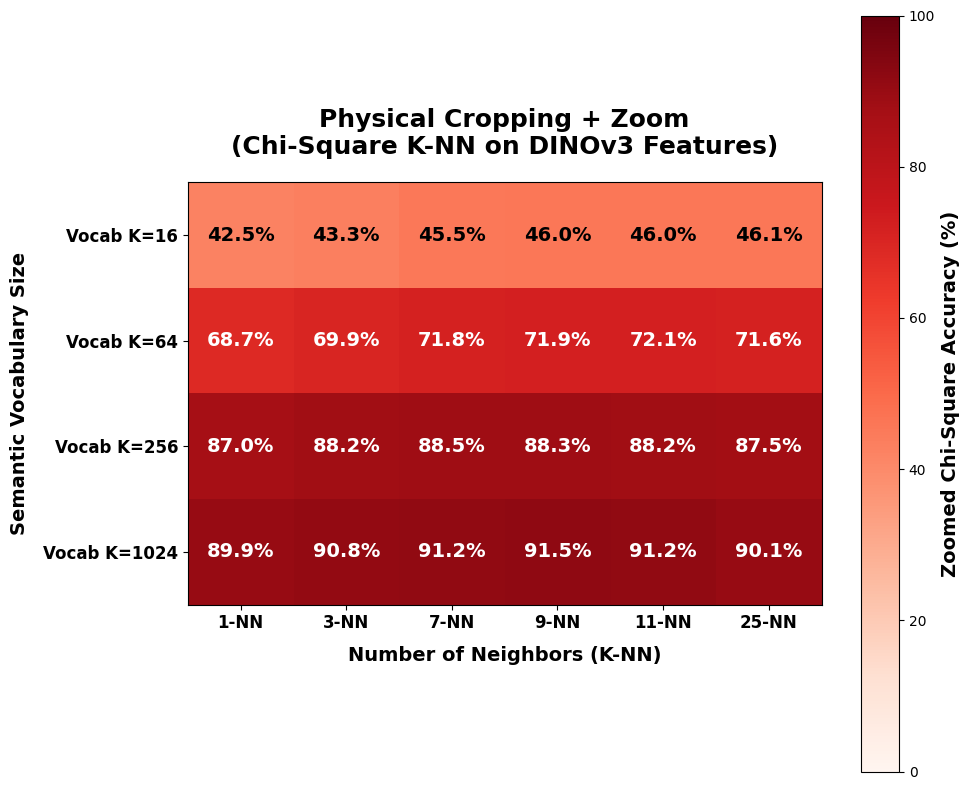

In [72]:
fig, ax = plt.subplots(figsize=(10, 8))

cax = ax.imshow(zoomed_chisq_results, cmap='Reds', vmin=0, vmax=100)
cbar = fig.colorbar(cax)
cbar.set_label('Zoomed Chi-Square Accuracy (%)', fontsize=14, fontweight='bold')

ax.set_xticks(np.arange(len(knn_neighbors)))
ax.set_yticks(np.arange(len(vocab_sizes)))
ax.set_xticklabels([f"{k}-NN" for k in knn_neighbors], fontsize=12, fontweight='bold')
ax.set_yticklabels([f"Vocab K={v}" for v in vocab_sizes], fontsize=12, fontweight='bold')
ax.set_xlabel("Number of Neighbors (K-NN)", fontsize=14, fontweight='bold', labelpad=10)
ax.set_ylabel("Semantic Vocabulary Size", fontsize=14, fontweight='bold', labelpad=10)

for i in range(len(vocab_sizes)):
    for j in range(len(knn_neighbors)):
        text_color = "white" if zoomed_chisq_results[i, j] > 50 else "black"
        ax.text(j, i, f"{zoomed_chisq_results[i, j]:.1f}%",
                ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

ax.set_title("Physical Cropping + Zoom\n(Chi-Square K-NN on DINOv3 Features)", fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

## **16. FAISS**

### **16.1 Init**

In [67]:
vocab_sizes = sorted(list(caltech_zoomed_train_hists.keys()))
knn_neighbors = [1, 3, 7, 9, 11, 25]

faiss_hellinger_results = np.zeros((len(vocab_sizes), len(knn_neighbors)))

### **16.2 Evaluation**

In [68]:
for i, vocab_k in enumerate(vocab_sizes):
    print(f"\n🧩 Processing Hellinger Distance for K = {vocab_k}...")
    start_time = time.time()

    # --- 1. GRAB RAW HISTOGRAMS ---
    train_raw = caltech_zoomed_train_hists[vocab_k].astype(np.float32)
    test_raw = caltech_zoomed_test_hists[vocab_k].astype(np.float32)

    # --- 2. THE HELLINGER TRICK (L1 Norm + Square Root) ---
    # Step A: L1 Normalize (so they sum to 1)
    train_l1 = train_raw / (np.sum(train_raw, axis=1, keepdims=True) + 1e-10)
    test_l1 = test_raw / (np.sum(test_raw, axis=1, keepdims=True) + 1e-10)

    # Step B: Take the Square Root
    train_hellinger = np.sqrt(train_l1)
    test_hellinger = np.sqrt(test_l1)

    # --- 3. BLAZING FAST FAISS L2 SEARCH ---
    d = train_hellinger.shape[1]
    index = faiss.IndexFlatL2(d)
    index.add(train_hellinger)

    k_max = max(knn_neighbors)
    distances, indices = index.search(test_hellinger, k_max)

    # --- 4. K-NN EVALUATION ---
    num_test = len(test_hellinger)
    for j, nn in enumerate(knn_neighbors):
        correct = 0
        for test_idx in range(num_test):
            nearest_indices = indices[test_idx, :nn]

            # Map back using safe indices
            nearest_labels = [caltech_full.y[safe_train_idx[idx]] for idx in nearest_indices]
            true_label = caltech_full.y[safe_test_idx[test_idx]]

            pred_label = Counter(nearest_labels).most_common(1)[0][0]
            if pred_label == true_label:
                correct += 1

        accuracy = (correct / num_test) * 100
        faiss_hellinger_results[i, j] = accuracy
        print(f"   -> {nn}-NN Accuracy: {accuracy:.1f}%")

    elapsed = time.time() - start_time
    print(f"   ⏱️ Completed K={vocab_k} in {elapsed:.4f} seconds!")


🧩 Processing Hellinger Distance for K = 16...
   -> 1-NN Accuracy: 42.1%
   -> 3-NN Accuracy: 43.3%
   -> 7-NN Accuracy: 45.7%
   -> 9-NN Accuracy: 46.5%
   -> 11-NN Accuracy: 46.4%
   -> 25-NN Accuracy: 46.0%
   ⏱️ Completed K=16 in 0.0970 seconds!

🧩 Processing Hellinger Distance for K = 64...
   -> 1-NN Accuracy: 68.2%
   -> 3-NN Accuracy: 70.1%
   -> 7-NN Accuracy: 71.7%
   -> 9-NN Accuracy: 71.7%
   -> 11-NN Accuracy: 71.1%
   -> 25-NN Accuracy: 71.3%
   ⏱️ Completed K=64 in 0.1045 seconds!

🧩 Processing Hellinger Distance for K = 256...
   -> 1-NN Accuracy: 87.2%
   -> 3-NN Accuracy: 88.5%
   -> 7-NN Accuracy: 88.4%
   -> 9-NN Accuracy: 88.5%
   -> 11-NN Accuracy: 88.2%
   -> 25-NN Accuracy: 88.0%
   ⏱️ Completed K=256 in 0.1509 seconds!

🧩 Processing Hellinger Distance for K = 1024...
   -> 1-NN Accuracy: 89.7%
   -> 3-NN Accuracy: 90.7%
   -> 7-NN Accuracy: 91.2%
   -> 9-NN Accuracy: 91.1%
   -> 11-NN Accuracy: 91.4%
   -> 25-NN Accuracy: 90.0%
   ⏱️ Completed K=1024 in 0.3565

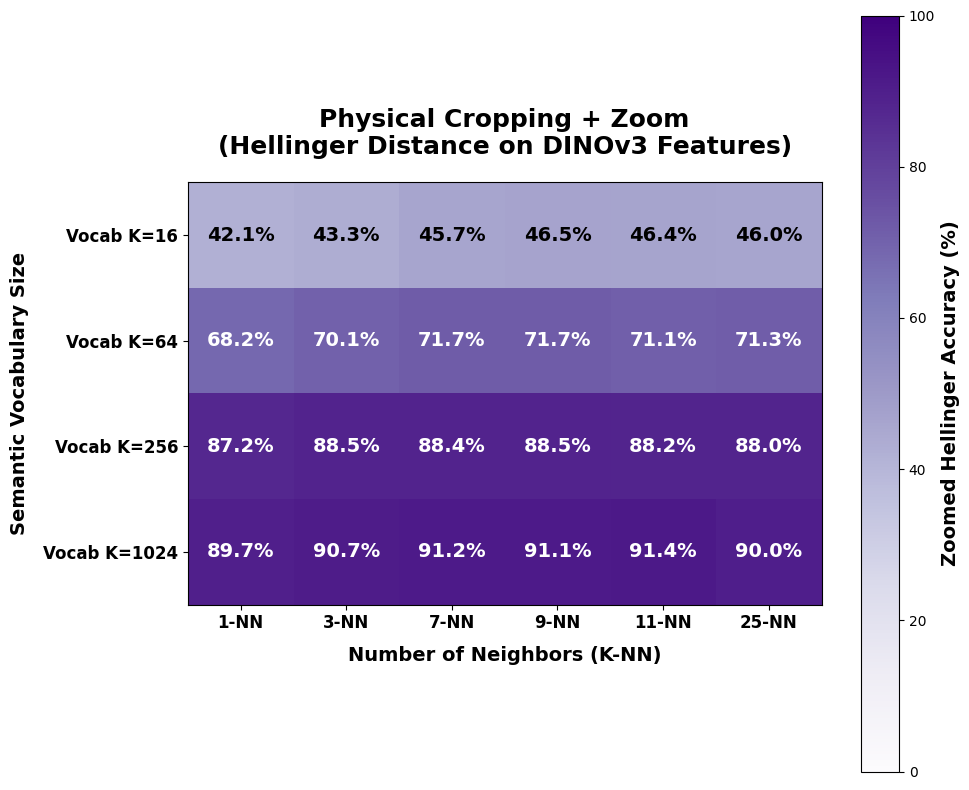

In [69]:
fig, ax = plt.subplots(figsize=(10, 8))

# Using 'Purples' for Hellinger
cax = ax.imshow(faiss_hellinger_results, cmap='Purples', vmin=0, vmax=100)
cbar = fig.colorbar(cax)
cbar.set_label('Zoomed Hellinger Accuracy (%)', fontsize=14, fontweight='bold')

ax.set_xticks(np.arange(len(knn_neighbors)))
ax.set_yticks(np.arange(len(vocab_sizes)))
ax.set_xticklabels([f"{k}-NN" for k in knn_neighbors], fontsize=12, fontweight='bold')
ax.set_yticklabels([f"Vocab K={v}" for v in vocab_sizes], fontsize=12, fontweight='bold')
ax.set_xlabel("Number of Neighbors (K-NN)", fontsize=14, fontweight='bold', labelpad=10)
ax.set_ylabel("Semantic Vocabulary Size", fontsize=14, fontweight='bold', labelpad=10)

for i in range(len(vocab_sizes)):
    for j in range(len(knn_neighbors)):
        text_color = "white" if faiss_hellinger_results[i, j] > 50 else "black"
        ax.text(j, i, f"{faiss_hellinger_results[i, j]:.1f}%",
                ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

ax.set_title("Physical Cropping + Zoom\n(Hellinger Distance on DINOv3 Features)", fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

### **17. TD-IDF + Cosine Similiarity**

### **17.1 Init**

In [74]:
vocab_sizes = sorted(list(caltech_zoomed_train_hists.keys()))
knn_neighbors = [1, 3, 7, 9, 11, 25]

zoomed_tfidf_results = np.zeros((len(vocab_sizes), len(knn_neighbors)))

### **17.2 Evaluation**

In [75]:
for i, vocab_k in enumerate(vocab_sizes):
    print(f"\n🧩 Processing TF-IDF for K = {vocab_k}...")
    start_time = time.time()


    train_raw = caltech_zoomed_train_hists[vocab_k]
    test_raw = caltech_zoomed_test_hists[vocab_k]

    # This automatically suppresses the massive "black background" bins
    tfidf_transformer = TfidfTransformer()
    train_tfidf = tfidf_transformer.fit_transform(train_raw).toarray().astype(np.float32)
    test_tfidf = tfidf_transformer.transform(test_raw).toarray().astype(np.float32)

    # L2 Normalizing vectors turns an Inner Product (Dot Product) search into pure Cosine Similarity!
    faiss.normalize_L2(train_tfidf)
    faiss.normalize_L2(test_tfidf)

    d = train_tfidf.shape[1]
    index = faiss.IndexFlatIP(d)
    index.add(train_tfidf)

    k_max = max(knn_neighbors)
    distances, indices = index.search(test_tfidf, k_max)

    num_test = len(test_tfidf)
    for j, nn in enumerate(knn_neighbors):
        correct = 0
        for test_idx in range(num_test):
            nearest_indices = indices[test_idx, :nn]

            # Map back using safe indices
            nearest_labels = [caltech_full.y[safe_train_idx[idx]] for idx in nearest_indices]
            true_label = caltech_full.y[safe_test_idx[test_idx]]

            pred_label = Counter(nearest_labels).most_common(1)[0][0]
            if pred_label == true_label:
                correct += 1

        accuracy = (correct / num_test) * 100
        zoomed_tfidf_results[i, j] = accuracy
        print(f"   -> {nn}-NN Accuracy: {accuracy:.1f}%")

    elapsed = time.time() - start_time
    print(f"   ⏱️ Completed K={vocab_k} in {elapsed:.4f} seconds!")


🧩 Processing TF-IDF for K = 16...
   -> 1-NN Accuracy: 42.1%
   -> 3-NN Accuracy: 42.7%
   -> 7-NN Accuracy: 45.2%
   -> 9-NN Accuracy: 45.4%
   -> 11-NN Accuracy: 45.3%
   -> 25-NN Accuracy: 45.0%
   ⏱️ Completed K=16 in 0.1021 seconds!

🧩 Processing TF-IDF for K = 64...
   -> 1-NN Accuracy: 68.4%
   -> 3-NN Accuracy: 70.2%
   -> 7-NN Accuracy: 70.4%
   -> 9-NN Accuracy: 70.7%
   -> 11-NN Accuracy: 69.6%
   -> 25-NN Accuracy: 69.4%
   ⏱️ Completed K=64 in 0.1234 seconds!

🧩 Processing TF-IDF for K = 256...
   -> 1-NN Accuracy: 87.2%
   -> 3-NN Accuracy: 87.4%
   -> 7-NN Accuracy: 87.7%
   -> 9-NN Accuracy: 88.3%
   -> 11-NN Accuracy: 88.4%
   -> 25-NN Accuracy: 87.5%
   ⏱️ Completed K=256 in 0.1871 seconds!

🧩 Processing TF-IDF for K = 1024...
   -> 1-NN Accuracy: 89.2%
   -> 3-NN Accuracy: 90.0%
   -> 7-NN Accuracy: 90.3%
   -> 9-NN Accuracy: 90.4%
   -> 11-NN Accuracy: 90.4%
   -> 25-NN Accuracy: 90.1%
   ⏱️ Completed K=1024 in 0.5105 seconds!


### **17.3 Plotting**

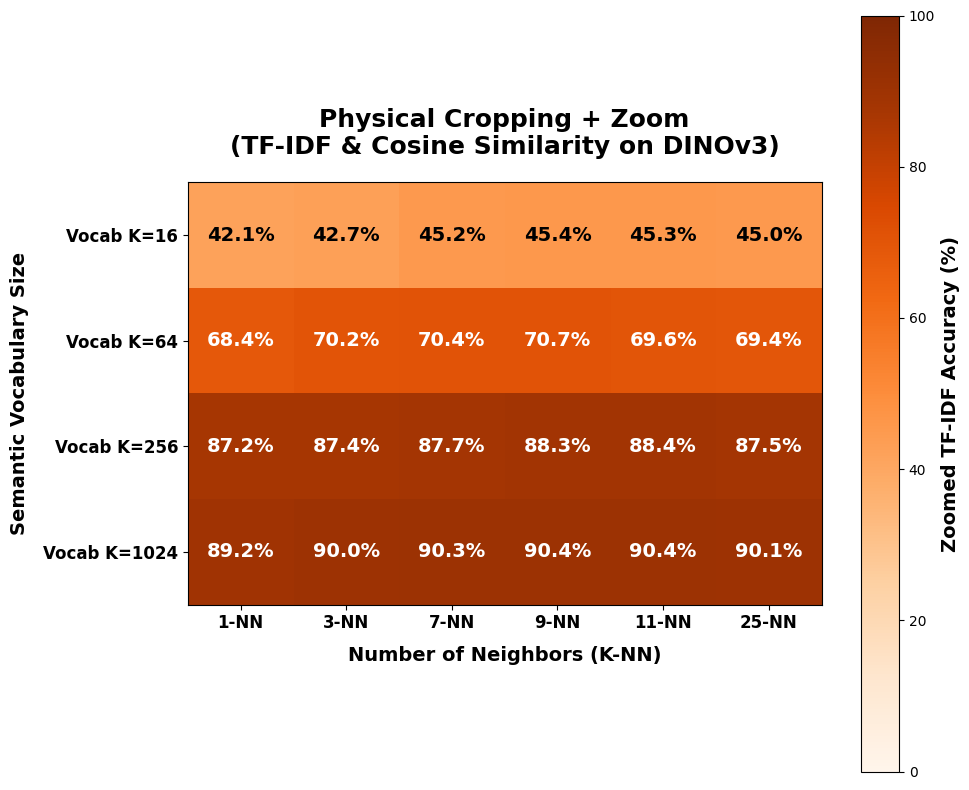

In [76]:
fig, ax = plt.subplots(figsize=(10, 8))

cax = ax.imshow(zoomed_tfidf_results, cmap='Oranges', vmin=0, vmax=100)
cbar = fig.colorbar(cax)
cbar.set_label('Zoomed TF-IDF Accuracy (%)', fontsize=14, fontweight='bold')

ax.set_xticks(np.arange(len(knn_neighbors)))
ax.set_yticks(np.arange(len(vocab_sizes)))
ax.set_xticklabels([f"{k}-NN" for k in knn_neighbors], fontsize=12, fontweight='bold')
ax.set_yticklabels([f"Vocab K={v}" for v in vocab_sizes], fontsize=12, fontweight='bold')
ax.set_xlabel("Number of Neighbors (K-NN)", fontsize=14, fontweight='bold', labelpad=10)
ax.set_ylabel("Semantic Vocabulary Size", fontsize=14, fontweight='bold', labelpad=10)

for i in range(len(vocab_sizes)):
    for j in range(len(knn_neighbors)):
        text_color = "white" if zoomed_tfidf_results[i, j] > 50 else "black"
        ax.text(j, i, f"{zoomed_tfidf_results[i, j]:.1f}%",
                ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

ax.set_title("Physical Cropping + Zoom\n(TF-IDF & Cosine Similarity on DINOv3)", fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()